The following datasets were analyzed:

- Avazu provides 40.4 million mobile ad impressions with click labels and categorical context features.
- Criteo provides 45.8 million ad impressions with click labels and numerical and categorical features. Its documented schema does not support constructing user histories, so its role here is feature interaction experiments.
- Amazon Electronics provides 1.7 million product reviews with ratings, reviewer/product identifiers and review dates.
- Taobao UserBehavior provides 100.2 million timestamped clicks, purchases, cart additions and favorites, with user, item and category identifiers.
- Taobao Ad Click provides 26.6 million ad impressions with observed click/non-click labels, user/ad identifiers, user profiles and ad attributes.
- KuaiRand-1K provides 11.8 million timestamped video interactions from 1,000 users, with viewing time and multiple feedback signals; histories reach over 100,000 earlier interactions.
- Tmall provides 54.9 million shopping actions across roughly six months, with item, category, brand and seller information.
- KuaiVideo provides 13.7 million video impressions with click, like and follow feedback, user/video identifiers and anonymized timestamps.

Each dataset analysis follows the same structure:

- Dataset description and column meanings.
- Data loading and feature type conversion.
- Dataset size, example rows and `df.describe(include='all')`.
- History construction where possible, a random whole history example, and statistics and distributions for history length and duration.
- Missing-value counts and percentages.
- Numerical anomaly counts and percentages using the 1.5 × IQR rule, where applicable.
- Categorical association matrices and numerical correlation matrices, where applicable.

# Avazu

Avazu is an advertising dataset used to **predict whether an ad impression will receive a click**. Each row represents one logged impression.

The columns describe:

- `id`: the impression’s identifier.
- `click`: the target, **1 for clicked, 0 for not clicked**.
- `hour`: when the impression occurred.
- `site_*`, `app_*`, `banner_pos`: the website/app context and banner position.
- `device_*`: device identifiers and characteristics.
- `C1`, `C14`–`C21`: anonymized categorical features.

In [2]:
from pathlib import Path
import pandas as pd
import pyarrow as pa
import pyarrow.csv as csv
from tqdm import tqdm

pa.set_cpu_count(4)
pd.set_option('display.max_columns', None)
path = Path('data/avazu/raw/train.csv')

In [3]:
integer_columns = ['C1', 'banner_pos', 'device_type', 'device_conn_type',
                   'C14', 'C15', 'C16', 'C17', 'C18', 'C19', 'C20', 'C21']
string_columns = ['id', 'hour', 'site_id', 'site_domain', 'site_category',
                  'app_id', 'app_domain', 'app_category',
                  'device_id', 'device_ip', 'device_model']
column_types = {name: pa.int32() for name in integer_columns}
column_types.update({name: pa.string() for name in string_columns})
column_types['click'] = pa.int8()

reader = csv.open_csv(path, read_options=csv.ReadOptions(block_size=32 << 20),
                      convert_options=csv.ConvertOptions(column_types=column_types))
batches = []
with tqdm(total=40_428_967, unit='rows', unit_scale=True, leave=False) as progress:
    for batch in reader:
        batches.append(batch)
        progress.update(batch.num_rows)
df = pa.Table.from_batches(batches).to_pandas(types_mapper=pd.ArrowDtype)
del batches, batch, reader

In [4]:
categorical_features = integer_columns + [c for c in string_columns if c not in ['id', 'hour']]

assert df.click.isin([0, 1]).all()
df['id'] = df.id.astype('string[pyarrow]')
df['hour'] = pd.to_datetime(df.hour, format='%y%m%d%H', utc=True)
df['click'] = df.click.astype('uint8[pyarrow]')
for column in tqdm(categorical_features, desc='Convert categorical features', leave=False):
    df[column] = df[column].astype('category')

df.dtypes.to_frame('dtype')

,dtype
id,string
click,uint8[pyarrow]
hour,"datetime64[us, UTC]"
C1,category
banner_pos,category
site_id,category
site_domain,category
site_category,category
app_id,category
app_domain,category


In [4]:
df.shape

(40428967, 24)

In [5]:
df.head()

,id,click,hour,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,app_category,device_id,device_ip,device_model,device_type,device_conn_type,C14,C15,C16,C17,C18,C19,C20,C21
0,1000009418151094273,0,2014-10-21 00:00:00+00:00,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,07d7df22,a99f214a,ddd2926e,44956a24,1,2,15706,320,50,1722,0,35,-1,79
1,10000169349117863715,0,2014-10-21 00:00:00+00:00,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,07d7df22,a99f214a,96809ac8,711ee120,1,0,15704,320,50,1722,0,35,100084,79
2,10000371904215119486,0,2014-10-21 00:00:00+00:00,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,07d7df22,a99f214a,b3cf8def,8a4875bd,1,0,15704,320,50,1722,0,35,100084,79
3,10000640724480838376,0,2014-10-21 00:00:00+00:00,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,07d7df22,a99f214a,e8275b8f,6332421a,1,0,15706,320,50,1722,0,35,100084,79
4,10000679056417042096,0,2014-10-21 00:00:00+00:00,1005,1,fe8cc448,9166c161,0569f928,ecad2386,7801e8d9,07d7df22,a99f214a,9644d0bf,779d90c2,1,0,18993,320,50,2161,0,35,-1,157


In [6]:
df.describe(include='all')

,id,click,hour,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,app_category,device_id,device_ip,device_model,device_type,device_conn_type,C14,C15,C16,C17,C18,C19,C20,C21
count,40428967,40428967.0,40428967,40428967.0,40428967.0,40428967,40428967,40428967,40428967,40428967,40428967,40428967,40428967,40428967,40428967.0,40428967.0,40428967.0,40428967.0,40428967.0,40428967.0,40428967.0,40428967.0,40428967.0,40428967.0
unique,40428967,<NA>,NaN,7.0,7.0,4737,7745,26,8552,559,36,2686408,6729486,8251,5.0,4.0,2626.0,8.0,9.0,435.0,4.0,68.0,172.0,60.0
top,1000009418151094273,<NA>,NaN,1005.0,0.0,85f751fd,c4e18dd6,50e219e0,ecad2386,7801e8d9,07d7df22,a99f214a,6b9769f2,8a4875bd,1.0,0.0,4687.0,320.0,50.0,1722.0,0.0,35.0,-1.0,23.0
freq,1,<NA>,NaN,37140632.0,29109590.0,14596137,15131739,16537234,25832830,27237087,26165592,33358308,208701,2455470,37304667.0,34886838.0,948215.0,37708959.0,38136554.0,4513492.0,16939044.0,12170630.0,18937918.0,8896205.0
mean,NaN,0.169806,2014-10-25 22:33:03.786209+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,0.0,2014-10-21 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,0.0,2014-10-23 04:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,0.0,2014-10-26 02:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,0.0,2014-10-28 14:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,NaN,1.0,2014-10-30 23:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


History is constructed from **earlier impressions with the same `device_id`**.

In [7]:
import random

counts = df.loc[df.device_id.ne('a99f214a'), ['device_id', 'hour']].groupby('device_id', observed=True).agg(
    impressions=('hour', 'size'), distinct_hours=('hour', 'nunique'))
eligible = counts.index[counts.impressions.between(3, 8) & counts.distinct_hours.ge(2)]
device_id = random.choice(eligible)
events = df.loc[df.device_id.eq(device_id)]
target = events.loc[events.hour.gt(events.hour.min())].sample(n=1)
history = events.loc[events.hour.lt(target.hour.iloc[0])].sort_values('hour')

example = pd.concat([history.assign(role='history'), target.assign(role='target')])
example = example[['role', 'hour', 'device_id', 'app_id', 'site_id', 'click']].copy()
example.reset_index(drop=True)

,role,hour,device_id,app_id,site_id,click
0,history,2014-10-26 17:00:00+00:00,70ce8a7b,442cfede,85f751fd,0
1,history,2014-10-26 17:00:00+00:00,70ce8a7b,442cfede,85f751fd,0
2,target,2014-10-26 20:00:00+00:00,70ce8a7b,442cfede,85f751fd,1


In [5]:
known_device = df.device_id.notna() & df.device_id.ne('a99f214a')
hours = df.loc[known_device, 'hour']
earlier_count = hours.groupby(df.loc[known_device, 'device_id'], sort=False, observed=True).rank(method='min') - 1
df['history_length'] = earlier_count.reindex(df.index).astype('int64[pyarrow]')
first_hour = hours.groupby(df.loc[known_device, 'device_id'], sort=False, observed=True).transform('min')
df['history_duration'] = (hours - first_hour).reindex(df.index)

In [6]:
history_length = df.history_length.dropna()
coverage = pd.Series({
    'Known device ID': int(known_device.sum()),
    'Unknown device ID': int((~known_device).sum()),
}, name='Impressions').to_frame()
coverage['Share (%)'] = (100 * coverage.Impressions / len(df)).round(2)
display(coverage)
def days_hours(value):
    if not isinstance(value, pd.Timedelta):
        return f'{value:,.0f}'
    total_hours = round(value.total_seconds() / 3600)
    days, hours = divmod(total_hours, 24)
    return f"{days} {'day' if days == 1 else 'days'} {hours} {'hour' if hours == 1 else 'hours'}"

quantiles = [.25, .5, .75, .9, .95, .99]
summary = history_length.describe(percentiles=quantiles).to_frame('history_length')
summary['history_duration, rounded to hours'] = df.history_duration.dropna().describe(percentiles=quantiles).map(days_hours)
summary.style.format({'history_length': '{:,.2f}'})

,Impressions,Share (%)
Known device ID,7070659,17.49
Unknown device ID,33358308,82.51


,history_length,"history_duration, rounded to hours"
count,"7,070,659.00","7,070,659"
mean,94.03,1 day 0 hours
std,977.99,2 days 2 hours
min,0.00,0 days 0 hours
25%,0.00,0 days 0 hours
50%,0.00,0 days 0 hours
75%,4.00,0 days 18 hours
90%,20.00,4 days 3 hours
95%,52.00,6 days 17 hours
99%,"1,703.00",8 days 13 hours


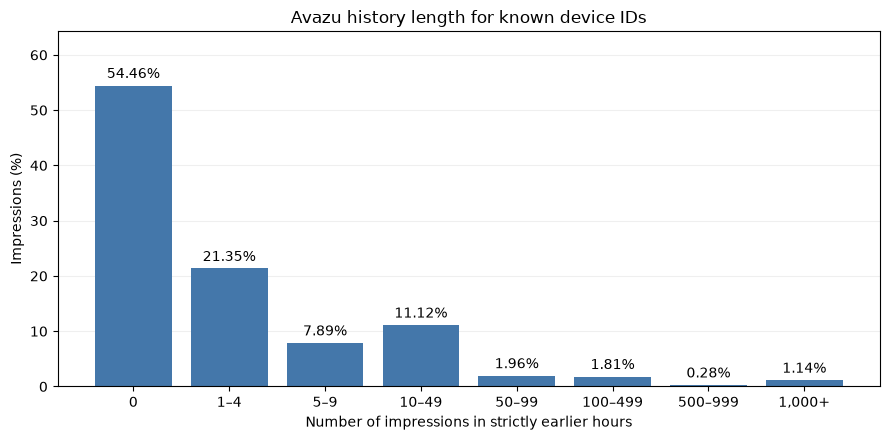

In [7]:
import matplotlib.pyplot as plt

bins = [-1, 0, 4, 9, 49, 99, 499, 999, float('inf')]
labels = ['0', '1–4', '5–9', '10–49', '50–99', '100–499', '500–999', '1,000+']
distribution = pd.cut(history_length, bins=bins, labels=labels).value_counts(sort=False)
percent = 100 * distribution / len(history_length)

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(labels, percent, color='#4477AA')
ax.bar_label(bars, labels=[f'{value:.2f}%' for value in percent], padding=3, fontsize=10)
ax.set(title='Avazu history length for known device IDs',
       xlabel='Number of impressions in strictly earlier hours',
       ylabel='Impressions (%)', ylim=(0, percent.max() * 1.18))
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

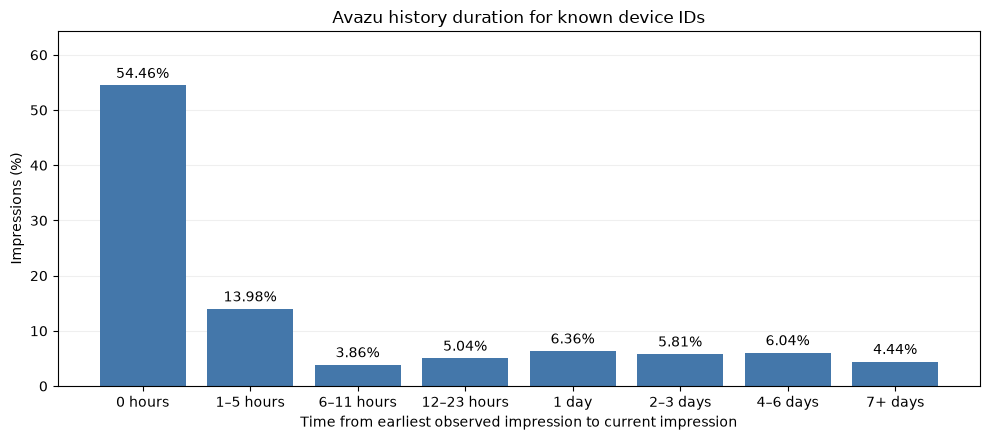

In [8]:
duration_hours = df.history_duration.dropna().dt.total_seconds() / 3600
bins = [-1, 0, 5, 11, 23, 47, 95, 167, float('inf')]
labels = ['0 hours', '1–5 hours', '6–11 hours', '12–23 hours', '1 day', '2–3 days', '4–6 days', '7+ days']
duration_distribution = pd.cut(duration_hours, bins=bins, labels=labels).value_counts(sort=False)
duration_percent = 100 * duration_distribution / len(duration_hours)

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(labels, duration_percent, color='#4477AA')
ax.bar_label(bars, labels=[f'{value:.2f}%' for value in duration_percent], padding=3, fontsize=10)
ax.set(title='Avazu history duration for known device IDs',
       xlabel='Time from earliest observed impression to current impression',
       ylabel='Impressions (%)', ylim=(0, duration_percent.max() * 1.18))
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

In [9]:
missing = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_%': 100 * df.isna().mean(),
})
missing.sort_values('missing_count', ascending=False).round(2)

,missing_count,missing_%
history_length,33358308,82.51
history_duration,33358308,82.51
hour,0,0.00
C1,0,0.00
banner_pos,0,0.00
site_id,0,0.00
site_domain,0,0.00
site_category,0,0.00
id,0,0.00
click,0,0.00


No missing values

In [2]:
outlier_features = []
# Anomaly flags retain the source values.
rows = []
for column in tqdm(outlier_features, desc='Numerical anomalies', leave=False):
    values = df[column].dropna()
    if values.empty:
        continue
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    if iqr <= 0:
        continue
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    anomalies = int(((values < lower) | (values > upper)).sum())
    rows.append({
        'feature': column, 'min': values.min(), 'max': values.max(),
        'lower bound': lower, 'upper bound': upper,
        'anomalies': anomalies, 'percent of anomalies': 100 * anomalies / len(values),
    })
if rows:
    print('Rule: 1.5 × IQR; percentages use non-missing values.')
    outliers = pd.DataFrame(rows).set_index('feature')
    display(outliers.style.format({
        'min': '{:,.2f}', 'max': '{:,.2f}', 'lower bound': '{:,.2f}',
        'upper bound': '{:,.2f}', 'anomalies': '{:,.0f}',
        'percent of anomalies': '{:.2f}',
    }))
elif outlier_features:
    print('No numerical features with a nonzero IQR.')
else:
    print('No raw numerical features to check.')

No raw numerical features to check.


In [5]:
import numpy as np
from itertools import combinations

matrix_features = [
    'click', 'banner_pos', 'device_type', 'device_conn_type',
    'site_category', 'app_category',
    'site_id', 'site_domain', 'app_id', 'app_domain', 'device_model',
    'C1', 'C14', 'C15', 'C16', 'C17', 'C18', 'C19', 'C20', 'C21',
]
matrix_sample = df[matrix_features].sample(n=min(1_000_000, len(df)), random_state=42)
codes, margins = {}, {}
for column in matrix_features:
    code, levels = pd.factorize(matrix_sample[column], sort=False)
    assert (code >= 0).all()
    codes[column] = code.astype('int64')
    margins[column] = np.bincount(code)

# Bias correction: https://stats.lse.ac.uk/bergsma/pdf/cramerV3.pdf
def corrected_cramers_v(x, y, row_counts, column_counts):
    n, r, k = len(x), len(row_counts), len(column_counts)
    if min(r, k) <= 1:
        return 0.0
    pairs, observed = np.unique(x * k + y, return_counts=True)
    expected = row_counts[pairs // k] * column_counts[pairs % k] / n
    phi_squared = max(0.0, (np.sum(observed.astype(float) ** 2 / expected) - n) / n)
    corrected_phi = max(0.0, phi_squared - (r - 1) * (k - 1) / (n - 1))
    corrected_r = r - (r - 1) ** 2 / (n - 1)
    corrected_k = k - (k - 1) ** 2 / (n - 1)
    denominator = min(corrected_r - 1, corrected_k - 1)
    return float(np.clip(np.sqrt(corrected_phi / denominator), 0, 1)) if denominator > 0 else 0.0

association_matrix = pd.DataFrame(np.eye(len(matrix_features)), index=matrix_features, columns=matrix_features)
for x, y in tqdm(list(combinations(matrix_features, 2)), desc="Cramer's V", unit='pair', leave=False):
    value = corrected_cramers_v(codes[x], codes[y], margins[x], margins[y])
    association_matrix.loc[x, y] = association_matrix.loc[y, x] = value

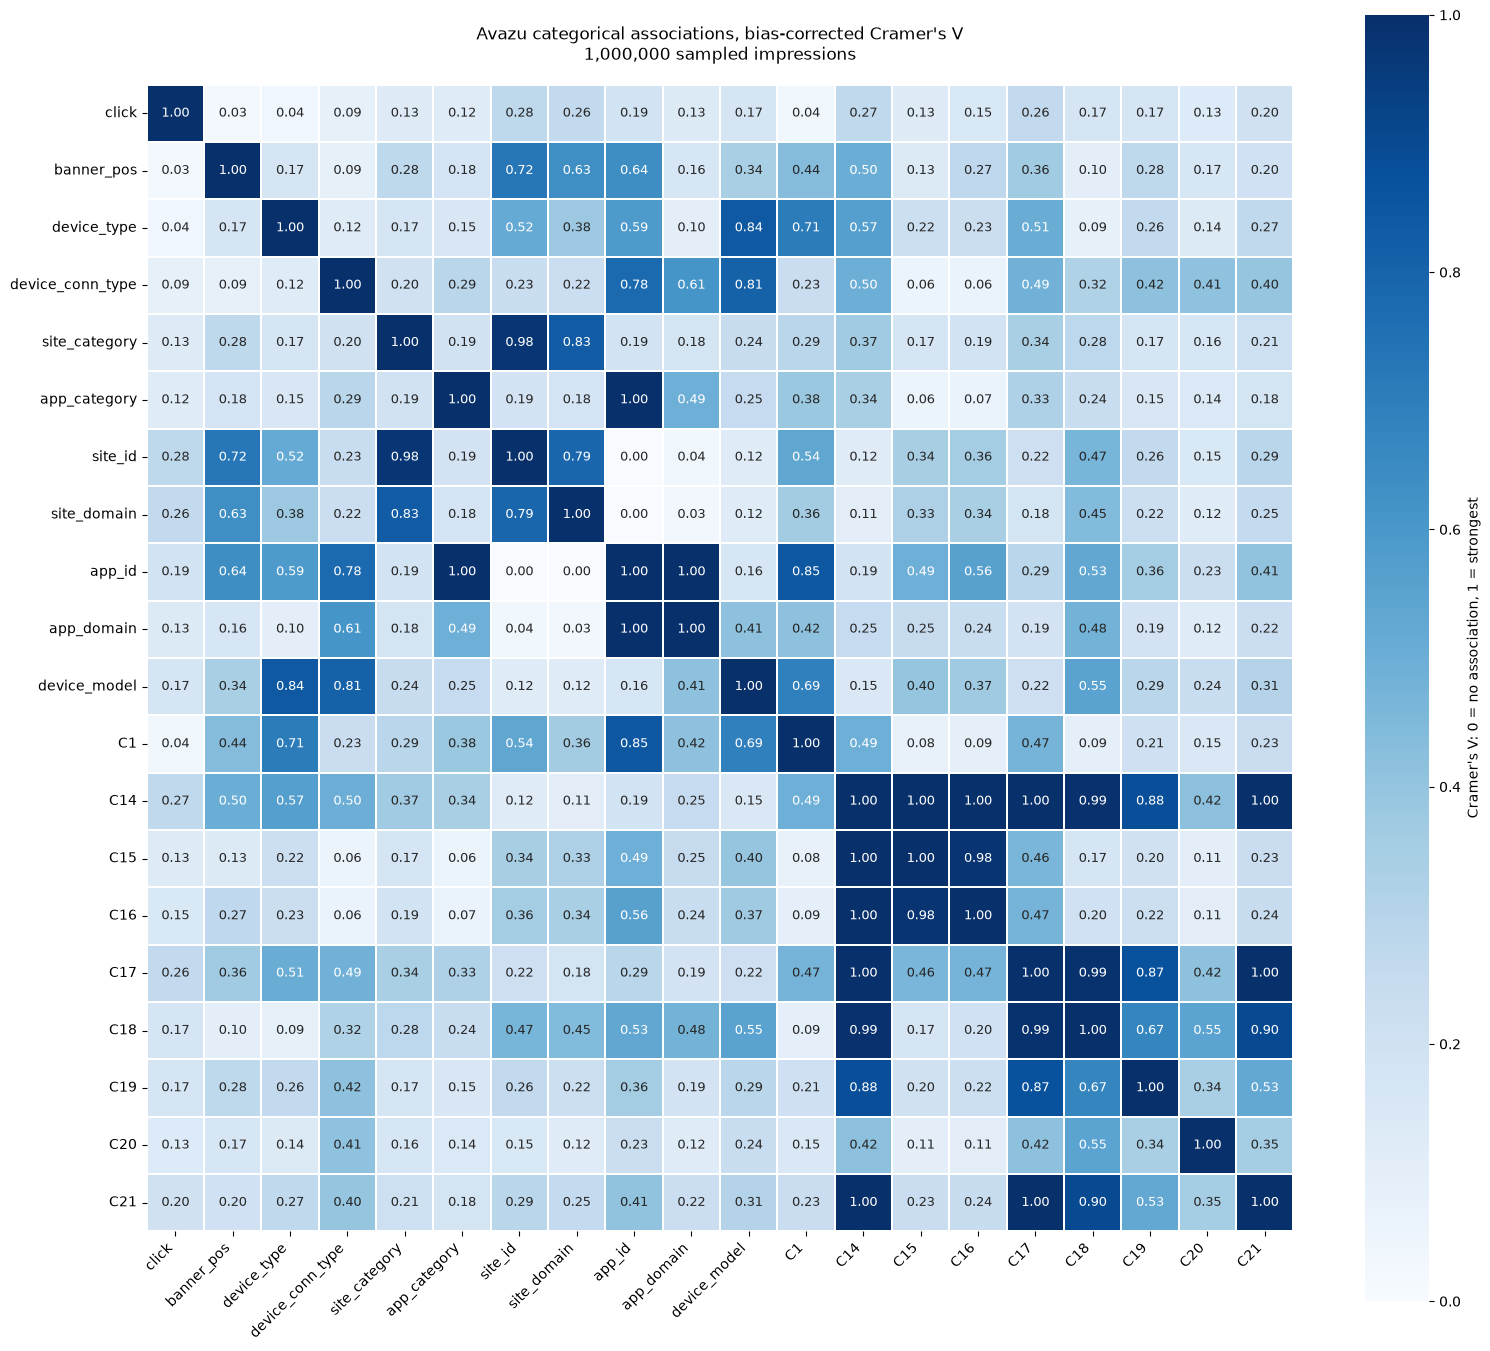

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(association_matrix, vmin=0, vmax=1, cmap='Blues', square=True,
            annot=True, fmt='.2f', annot_kws={'fontsize': 9}, linewidths=.25,
            cbar_kws={'label': "Cramer's V: 0 = no association, 1 = strongest"}, ax=ax)
ax.set_title(f"Avazu categorical associations, bias-corrected Cramer's V\n{len(matrix_sample):,} sampled impressions", pad=18)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_xlabel('')
ax.set_ylabel('')
fig.tight_layout()
plt.show()

# Criteo

Criteo is an advertising dataset used to **predict whether an ad impression will receive a click**. Each row represents one served ad.

The columns describe:

- `label`: the target, **1 for clicked, 0 for not clicked**.
- `I1`–`I13`: anonymized numerical features, mostly counts.
- `C1`–`C26`: anonymized categorical features.

In [2]:
import gc
from pathlib import Path
import pandas as pd
import pyarrow as pa
import pyarrow.csv as csv
from tqdm import tqdm

df = None
_ = gc.collect()
pa.default_memory_pool().release_unused()
pa.set_cpu_count(4)
pd.set_option('display.max_columns', None)
path = Path('data/criteo/raw/train.txt')

In [3]:
numerical_features = [f'I{i}' for i in range(1, 14)]
categorical_features = [f'C{i}' for i in range(1, 27)]
columns = ['label'] + numerical_features + categorical_features
column_types = {name: pa.int64() for name in numerical_features}
column_types.update({name: pa.string() for name in categorical_features})
column_types['label'] = pa.int8()

reader = csv.open_csv(path,
    read_options=csv.ReadOptions(column_names=columns, block_size=32 << 20),
    parse_options=csv.ParseOptions(delimiter='	', quote_char=False, ignore_empty_lines=False),
    convert_options=csv.ConvertOptions(column_types=column_types, null_values=[''], strings_can_be_null=True))
batches = []
with tqdm(total=45_840_617, unit='rows', unit_scale=True, leave=False) as progress:
    for batch in reader:
        batches.append(batch)
        progress.update(batch.num_rows)
df = pa.Table.from_batches(batches).to_pandas(types_mapper=pd.ArrowDtype)
del batches, batch, reader

In [4]:
assert df.label.isin([0, 1]).all()
df['label'] = df.label.astype('uint8[pyarrow]')
for column in tqdm(categorical_features, desc='Convert categorical features', leave=False):
    df[column] = df[column].astype('category')

df.dtypes.to_frame('dtype')

,dtype
label,uint8[pyarrow]
I1,int64[pyarrow]
I2,int64[pyarrow]
I3,int64[pyarrow]
I4,int64[pyarrow]
I5,int64[pyarrow]
I6,int64[pyarrow]
I7,int64[pyarrow]
I8,int64[pyarrow]
I9,int64[pyarrow]


In [5]:
df.shape

(45840617, 40)

In [6]:
df.head()

,label,I1,I2,I3,I4,I5,I6,I7,I8,I9,I10,I11,I12,I13,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,C15,C16,C17,C18,C19,C20,C21,C22,C23,C24,C25,C26
0,0,1,1,5,0,1382,4,15,2,181,1,2,<NA>,2,68fd1e64,80e26c9b,fb936136,7b4723c4,25c83c98,7e0ccccf,de7995b8,1f89b562,a73ee510,a8cd5504,b2cb9c98,37c9c164,2824a5f6,1adce6ef,8ba8b39a,891b62e7,e5ba7672,f54016b9,21ddcdc9,b1252a9d,07b5194c,<NA>,3a171ecb,c5c50484,e8b83407,9727dd16
1,0,2,0,44,1,102,8,2,2,4,1,1,<NA>,4,68fd1e64,f0cf0024,6f67f7e5,41274cd7,25c83c98,fe6b92e5,922afcc0,0b153874,a73ee510,2b53e5fb,4f1b46f3,623049e6,d7020589,b28479f6,e6c5b5cd,c92f3b61,07c540c4,b04e4670,21ddcdc9,5840adea,60f6221e,<NA>,3a171ecb,43f13e8b,e8b83407,731c3655
2,0,2,0,1,14,767,89,4,2,245,1,3,3,45,287e684f,0a519c5c,02cf9876,c18be181,25c83c98,7e0ccccf,c78204a1,0b153874,a73ee510,3b08e48b,5f5e6091,8fe001f4,aa655a2f,07d13a8f,6dc710ed,36103458,8efede7f,3412118d,<NA>,<NA>,e587c466,ad3062eb,3a171ecb,3b183c5c,<NA>,<NA>
3,0,<NA>,893,<NA>,<NA>,4392,<NA>,0,0,0,<NA>,0,<NA>,<NA>,68fd1e64,2c16a946,a9a87e68,2e17d6f6,25c83c98,fe6b92e5,2e8a689b,0b153874,a73ee510,efea433b,e51ddf94,a30567ca,3516f6e6,07d13a8f,18231224,52b8680f,1e88c74f,74ef3502,<NA>,<NA>,6b3a5ca6,<NA>,3a171ecb,9117a34a,<NA>,<NA>
4,0,3,-1,<NA>,0,2,0,3,0,0,1,1,<NA>,0,8cf07265,ae46a29d,c81688bb,f922efad,25c83c98,13718bbd,ad9fa255,0b153874,a73ee510,5282c137,e5d8af57,66a76a26,f06c53ac,1adce6ef,8ff4b403,01adbab4,1e88c74f,26b3c7a7,<NA>,<NA>,21c9516a,<NA>,32c7478e,b34f3128,<NA>,<NA>


In [7]:
df.describe(include='all')

,label,I1,I2,I3,I4,I5,I6,I7,I8,I9,I10,I11,I12,I13,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,C15,C16,C17,C18,C19,C20,C21,C22,C23,C24,C25,C26
count,45840617.0,25047061.0,45840617.0,36001170.0,35903248.0,44657500.0,35588289.0,43857751.0,45817844.0,43857751.0,25047061.0,43857751.0,10768965.0,35903248.0,45840617,45840617,44281144,44281144,45840617,40299992,45840617,45840617,45840617,45840617,45840617,44281144,45840617,45840617,45840617,44281144,45840617,45840617,25667759,25667759,44281144,10885544,45840617,44281144,25667759,25667759
unique,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,1460,583,10131226,2202607,305,23,12517,633,3,93145,5683,8351592,3194,27,14992,5461305,10,5652,2172,3,7046546,17,15,286180,104,142571
top,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,05db9164,38a947a1,d032c263,c18be181,25c83c98,7e0ccccf,1c86e0eb,0b153874,a73ee510,3b08e48b,755e4a50,dfbb09fb,5978055e,b28479f6,2d0bb053,84898b2a,e5ba7672,e88ffc9d,21ddcdc9,b1252a9d,0014c32a,ad3062eb,32c7478e,3fdb382b,001f3601,49d68486
freq,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,22950860,5245774,1141289,1636423,30772137,18166950,955418,27232196,41200152,10157763,1458428,1141289,1458428,16029055,684365,1141316,21153559,1450322,15800355,8702869,1141289,6253065,20170568,2400439,6557407,1888619
mean,0.256223,3.502413,105.84842,26.913041,7.32268,18538.991665,116.061851,16.33313,12.517042,106.109823,0.617529,2.732834,0.991036,8.217461,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.436547,9.429076,391.457823,397.972583,8.793231,69394.601846,382.566449,66.049755,16.688885,220.283094,0.684051,5.199071,5.597724,16.211933,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.0,0.0,-3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.0,0.0,0.0,2.0,2.0,328.0,8.0,1.0,2.0,10.0,0.0,1.0,0.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.0,1.0,3.0,6.0,4.0,2813.0,32.0,3.0,7.0,38.0,1.0,1.0,0.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.0,3.0,35.0,18.0,10.0,10131.0,102.0,11.0,19.0,110.0,1.0,3.0,1.0,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


The release does not identify users or timestamps, so user histories cannot be constructed.

In [8]:
missing = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_%': 100 * df.isna().mean(),
})
missing.sort_values('missing_count', ascending=False).round(2)

,missing_count,missing_%
I12,35071652,76.51
C22,34955073,76.25
I1,20793556,45.36
I10,20793556,45.36
C26,20172858,44.01
C25,20172858,44.01
C19,20172858,44.01
C20,20172858,44.01
I6,10252328,22.37
I4,9937369,21.68


In [5]:
outlier_features = ['I1', 'I2', 'I3', 'I4', 'I5', 'I6', 'I7', 'I8', 'I9', 'I10', 'I11', 'I12', 'I13']
# Anomaly flags retain the source values.
rows = []
for column in tqdm(outlier_features, desc='Numerical anomalies', leave=False):
    values = df[column].dropna()
    if values.empty:
        continue
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    if iqr <= 0:
        continue
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    anomalies = int(((values < lower) | (values > upper)).sum())
    rows.append({
        'feature': column, 'min': values.min(), 'max': values.max(),
        'lower bound': lower, 'upper bound': upper,
        'anomalies': anomalies, 'percent of anomalies': 100 * anomalies / len(values),
    })
if rows:
    print('Rule: 1.5 × IQR; percentages use non-missing values.')
    outliers = pd.DataFrame(rows).set_index('feature')
    display(outliers.style.format({
        'min': '{:,.2f}', 'max': '{:,.2f}', 'lower bound': '{:,.2f}',
        'upper bound': '{:,.2f}', 'anomalies': '{:,.0f}',
        'percent of anomalies': '{:.2f}',
    }))
elif outlier_features:
    print('No numerical features with a nonzero IQR.')
else:
    print('No raw numerical features to check.')

Rule: 1.5 × IQR; percentages use non-missing values.


,min,max,lower bound,upper bound,anomalies,percent of anomalies
feature,,,,,,
I1,0.00,"5,775.00",-4.50,7.50,"3,014,699",12.04
I2,-3.00,"257,675.00",-52.50,87.50,"7,307,806",15.94
I3,0.00,"65,535.00",-22.00,42.00,"3,750,710",10.42
I4,0.00,969.00,-10.00,22.00,"2,362,889",6.58
I5,0.00,"23,159,456.00","-14,376.50","24,835.50","5,891,996",13.19
I6,0.00,"431,037.00",-133.00,243.00,"4,036,061",11.34
I7,0.00,"56,311.00",-14.00,26.00,"5,555,379",12.67
I8,0.00,"6,047.00",-23.50,44.50,"1,492,505",3.26
I9,0.00,"29,019.00",-140.00,260.00,"4,462,309",10.17


In [9]:
import numpy as np
from itertools import combinations

matrix_features = ['label', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'C15', 'C16', 'C17', 'C18', 'C19', 'C20', 'C21', 'C22', 'C23', 'C24', 'C25', 'C26']

matrix_sample = df[matrix_features].sample(n=min(1_000_000, len(df)), random_state=42)
codes, margins = {}, {}
# Missing values form a category in this matrix.
for column in matrix_features:
    code, levels = pd.factorize(matrix_sample[column], sort=False, use_na_sentinel=False)
    assert (code >= 0).all()
    codes[column] = code.astype('int64')
    margins[column] = np.bincount(code)

# Bias correction: https://stats.lse.ac.uk/bergsma/pdf/cramerV3.pdf
def corrected_cramers_v(x, y, row_counts, column_counts):
    n, r, k = len(x), len(row_counts), len(column_counts)
    if min(r, k) <= 1:
        return 0.0
    pairs, observed = np.unique(x * k + y, return_counts=True)
    expected = row_counts[pairs // k] * column_counts[pairs % k] / n
    phi_squared = max(0.0, (np.sum(observed.astype(float) ** 2 / expected) - n) / n)
    corrected_phi = max(0.0, phi_squared - (r - 1) * (k - 1) / (n - 1))
    corrected_r = r - (r - 1) ** 2 / (n - 1)
    corrected_k = k - (k - 1) ** 2 / (n - 1)
    denominator = min(corrected_r - 1, corrected_k - 1)
    return float(np.clip(np.sqrt(corrected_phi / denominator), 0, 1)) if denominator > 0 else 0.0

association_matrix = pd.DataFrame(np.eye(len(matrix_features)), index=matrix_features, columns=matrix_features)
for x, y in tqdm(list(combinations(matrix_features, 2)), desc="Cramer's V", unit='pair', leave=False):
    value = corrected_cramers_v(codes[x], codes[y], margins[x], margins[y])
    association_matrix.loc[x, y] = association_matrix.loc[y, x] = value

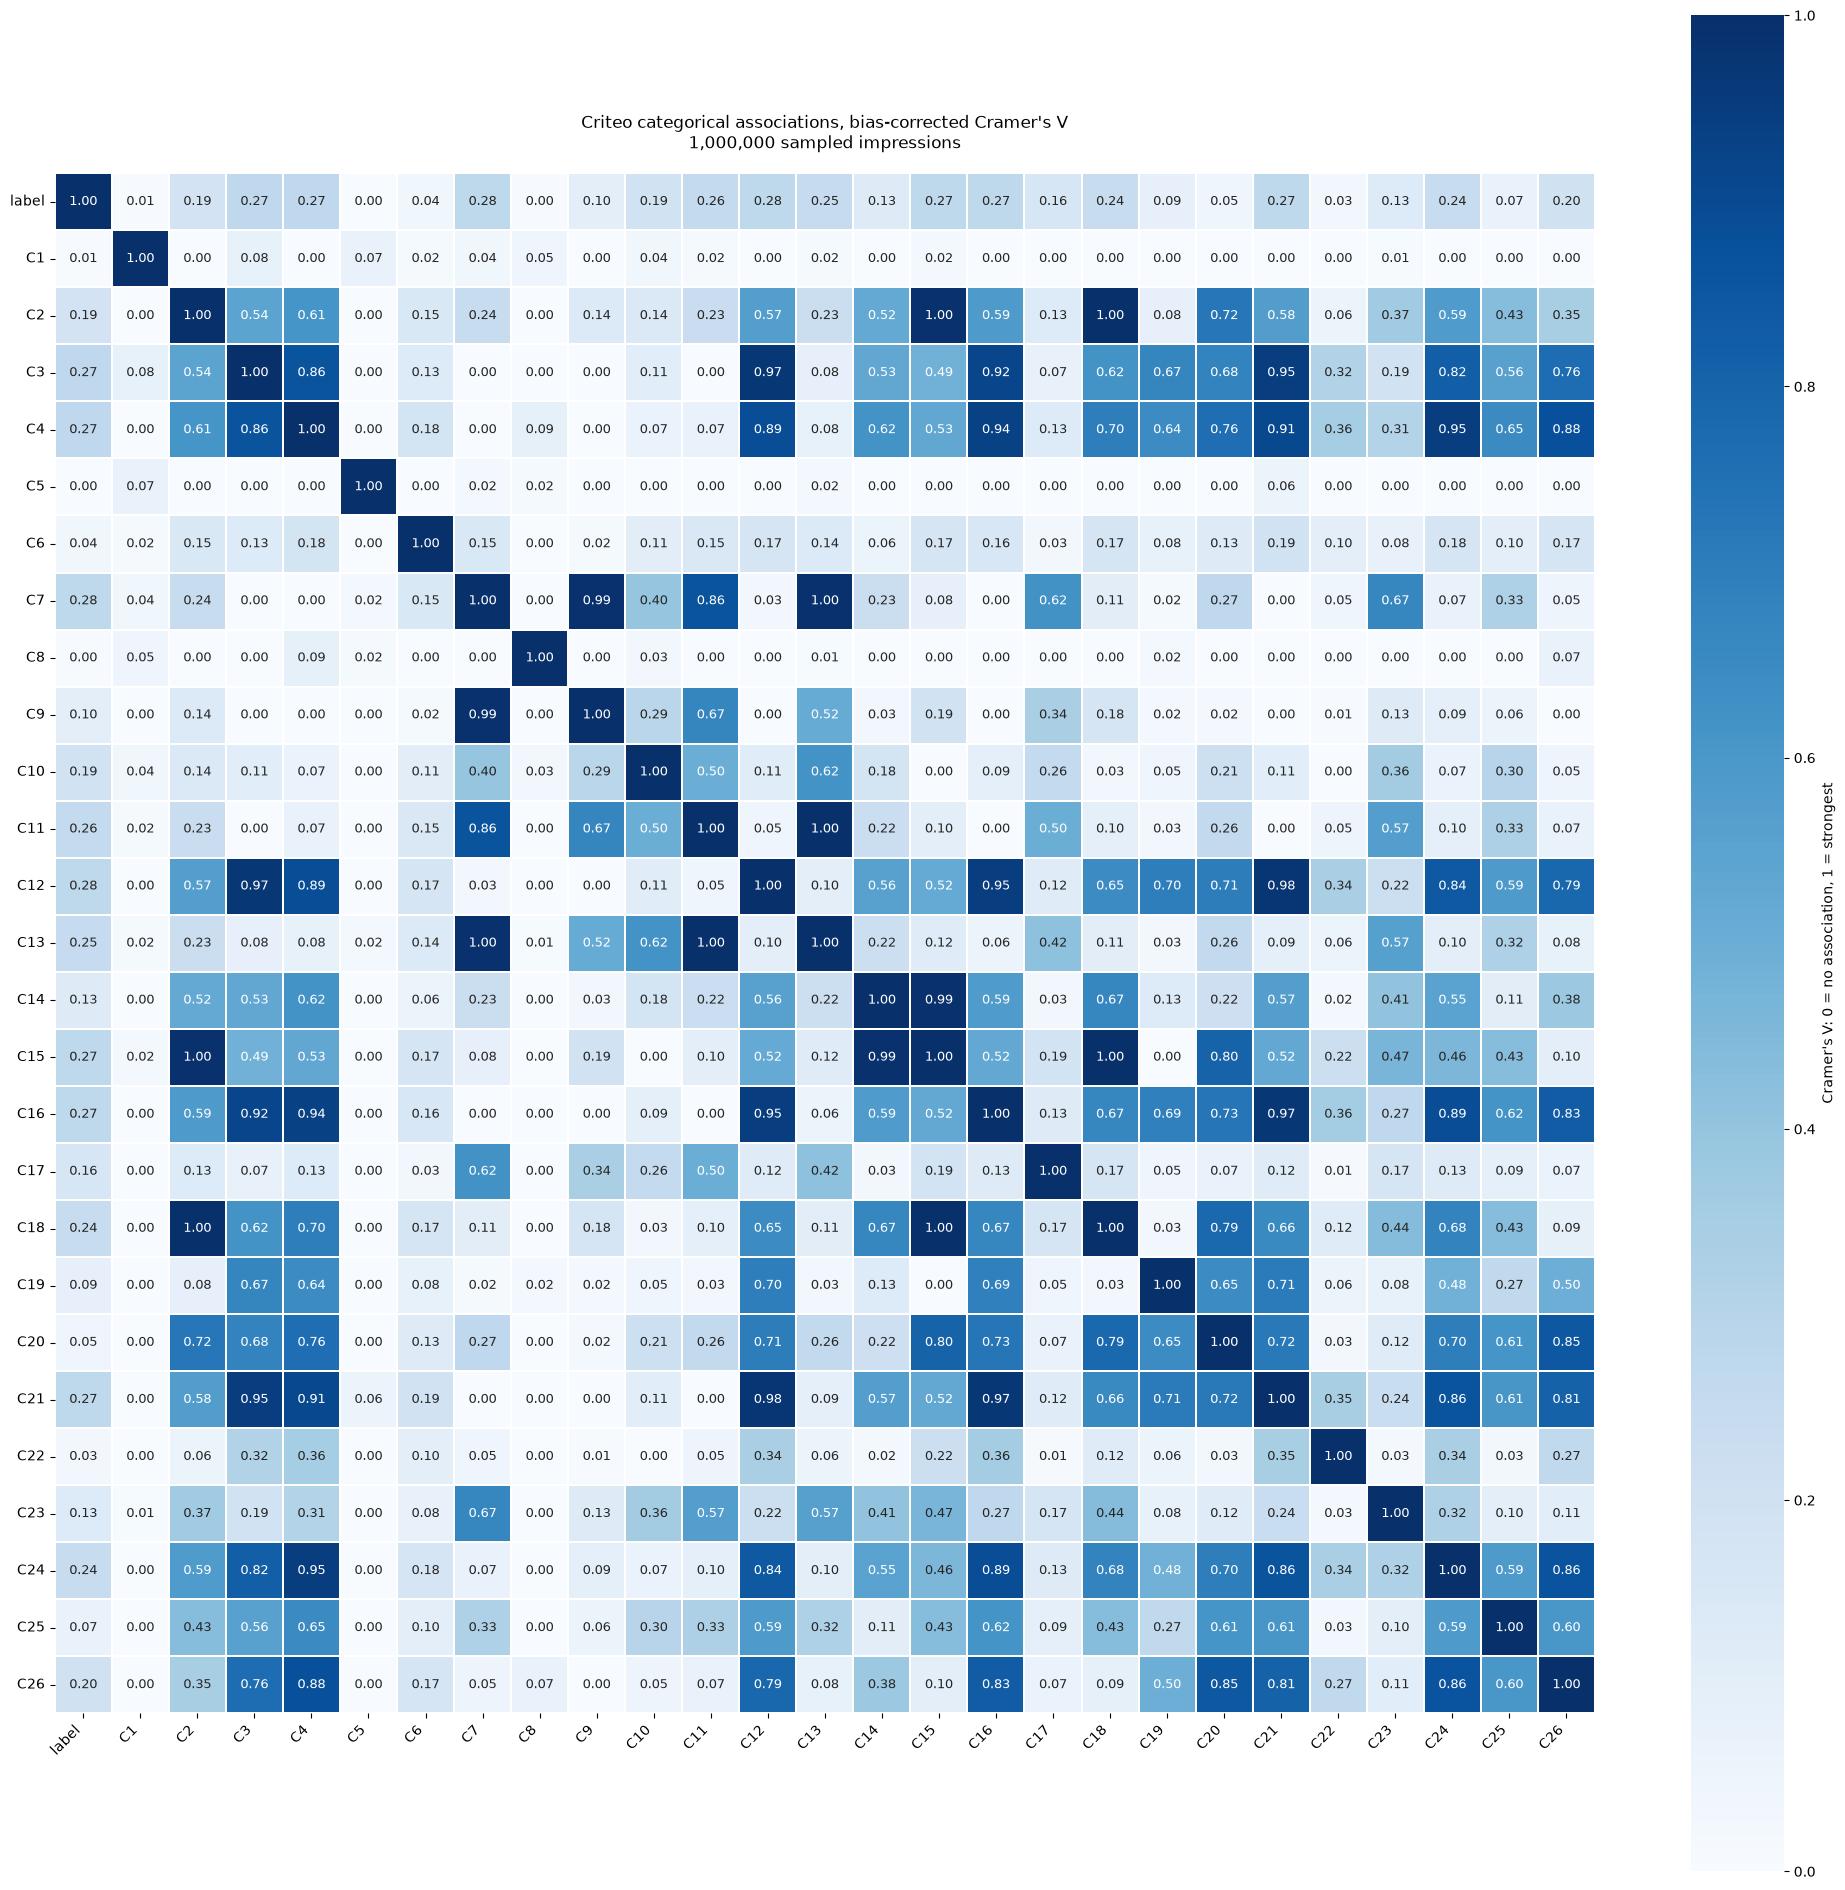

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(20.0, 19.0))
sns.heatmap(association_matrix, vmin=0, vmax=1, cmap='Blues', square=True,
            annot=True, fmt='.2f', annot_kws={'fontsize': 9}, linewidths=.25,
            cbar_kws={'label': "Cramer's V: 0 = no association, 1 = strongest"}, ax=ax)
ax.set_title(f"Criteo categorical associations, bias-corrected Cramer's V\n{len(matrix_sample):,} sampled impressions", pad=18)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_xlabel('')
ax.set_ylabel('')
fig.tight_layout()
plt.show()

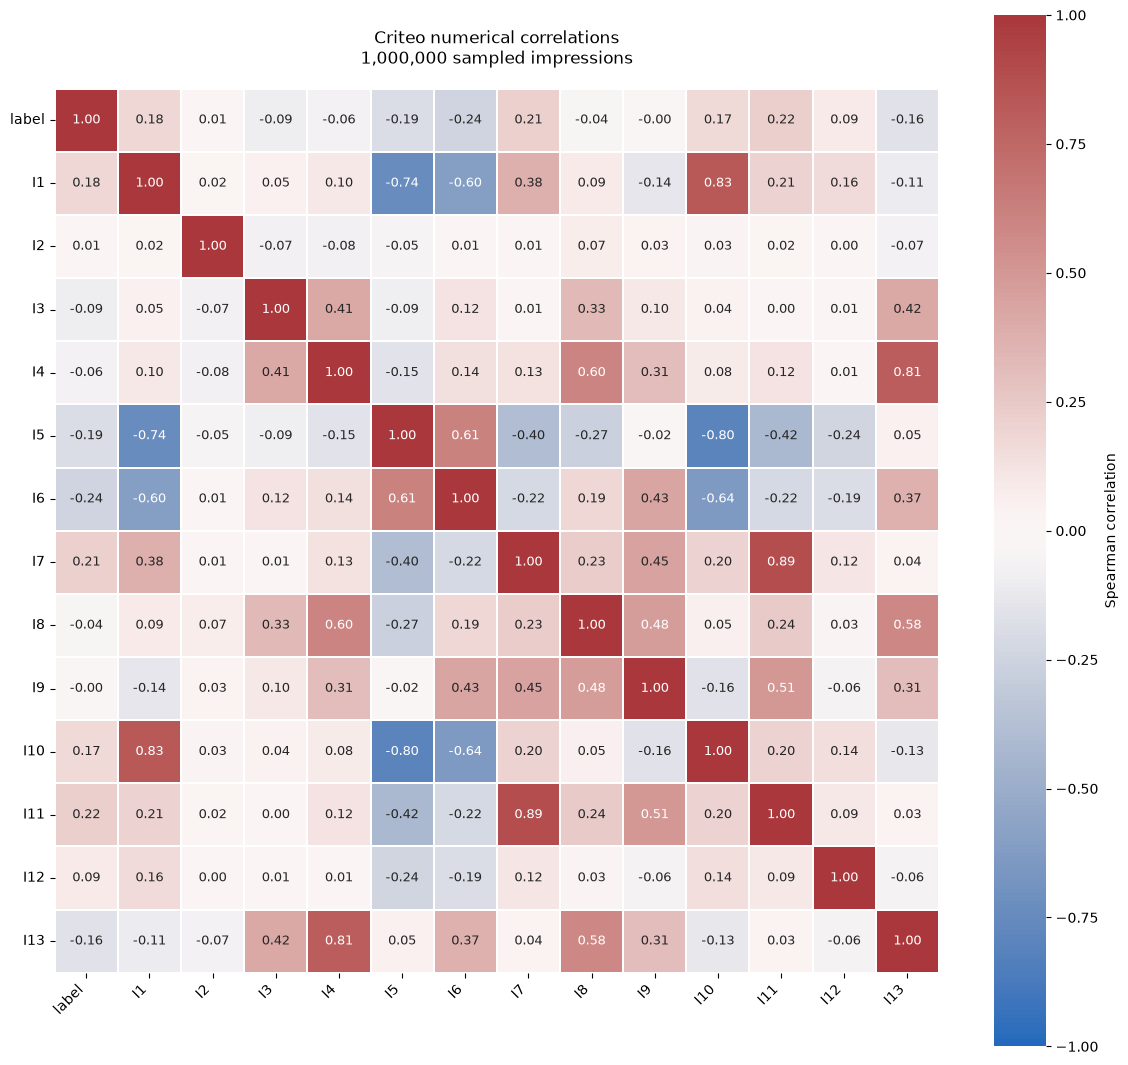

In [11]:
numerical_features = ['label', 'I1', 'I2', 'I3', 'I4', 'I5', 'I6', 'I7', 'I8', 'I9', 'I10', 'I11', 'I12', 'I13']
numerical_sample = df[numerical_features].sample(n=min(1_000_000, len(df)), random_state=42)
numerical_correlation = numerical_sample.corr(method='spearman')

fig, ax = plt.subplots(figsize=(11.8, 10.8))
sns.heatmap(numerical_correlation, vmin=-1, vmax=1, center=0, cmap='vlag', square=True,
            annot=True, fmt='.2f', annot_kws={'fontsize': 9}, linewidths=.25,
            cbar_kws={'label': 'Spearman correlation'}, ax=ax)
ax.set_title(f'Criteo numerical correlations\n{len(numerical_sample):,} sampled impressions', pad=18)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_xlabel('')
ax.set_ylabel('')
fig.tight_layout()
plt.show()

# Amazon Electronics

Amazon Electronics contains **product reviews and ratings**. Each row represents one review.

The columns describe:

- `reviewerID`, `asin`: the reviewer and product identifiers.
- `overall`: the target rating, **1 to 5 stars**.
- `reviewerName`, `reviewText`, `summary`: the reviewer name, review and title.
- `helpful_yes`, `helpful_total`: helpful votes and total votes, split from `helpful`.
- `unixReviewTime`, `reviewTime`: the review date.

In [2]:
import gc
from pathlib import Path
import pandas as pd
import pyarrow as pa
import pyarrow.csv as csv
from tqdm import tqdm

df = None
_ = gc.collect()
pa.default_memory_pool().release_unused()
pa.set_cpu_count(4)
pd.set_option('display.max_columns', None)
path = Path('data/amazon_electronics/raw/reviews_Electronics_5.json.gz')

In [3]:
import pyarrow.json as paj
import pyarrow.compute as pc

schema = pa.schema([
    ('reviewerID', pa.string()), ('asin', pa.string()), ('reviewerName', pa.string()),
    ('helpful', pa.list_(pa.int64())), ('reviewText', pa.string()), ('overall', pa.float64()),
    ('summary', pa.string()), ('unixReviewTime', pa.int64()), ('reviewTime', pa.string()),
])
batches = []
with pa.input_stream(str(path), compression='gzip') as source:
    reader = paj.open_json(source, read_options=paj.ReadOptions(block_size=32 << 20),
                           parse_options=paj.ParseOptions(explicit_schema=schema))
    with tqdm(total=1_689_188, unit='reviews', unit_scale=True, leave=False) as progress:
        for batch in reader:
            batches.append(batch)
            progress.update(batch.num_rows)
table = pa.Table.from_batches(batches)
table = table.append_column('helpful_yes', pc.list_element(table['helpful'], 0))
table = table.append_column('helpful_total', pc.list_element(table['helpful'], 1)).drop(['helpful'])
df = table.to_pandas(types_mapper=pd.ArrowDtype)
del batches, batch, reader, table

In [4]:
categorical_features = ['reviewerID', 'asin']
assert df.overall.isin([1, 2, 3, 4, 5]).all()
df['overall'] = df.overall.astype('uint8[pyarrow]')
df['unixReviewTime'] = pd.to_datetime(df.unixReviewTime, unit='s', utc=True)
df['reviewTime'] = pd.to_datetime(df.reviewTime, format='%m %d, %Y', utc=True)
for column in tqdm(categorical_features, desc='Convert categorical features', leave=False):
    df[column] = df[column].astype('category')
for column in ['reviewerName', 'reviewText', 'summary']:
    df[column] = df[column].astype('string[pyarrow]')
    df[column] = df[column].mask(df[column].str.strip().eq(''), pd.NA)

df.dtypes.to_frame('dtype')

,dtype
reviewerID,category
asin,category
reviewerName,string
reviewText,string
overall,uint8[pyarrow]
summary,string
unixReviewTime,"datetime64[us, UTC]"
reviewTime,"datetime64[us, UTC]"
helpful_yes,int64[pyarrow]
helpful_total,int64[pyarrow]


In [5]:
df.shape

(1689188, 10)

In [6]:
df.head()

,reviewerID,asin,reviewerName,reviewText,overall,summary,unixReviewTime,reviewTime,helpful_yes,helpful_total
0,AO94DHGC771SJ,0528881469,amazdnu,We got this GPS for my husband who is an (OTR)...,5,Gotta have GPS!,2013-06-02 00:00:00+00:00,2013-06-02 00:00:00+00:00,0,0
1,AMO214LNFCEI4,0528881469,Amazon Customer,"I'm a professional OTR truck driver, and I bou...",1,Very Disappointed,2010-11-25 00:00:00+00:00,2010-11-25 00:00:00+00:00,12,15
2,A3N7T0DY83Y4IG,0528881469,C. A. Freeman,"Well, what can I say. I've had this unit in m...",3,1st impression,2010-09-09 00:00:00+00:00,2010-09-09 00:00:00+00:00,43,45
3,A1H8PY3QHMQQA0,0528881469,"Dave M. Shaw ""mack dave""","Not going to write a long review, even thought...",2,"Great grafics, POOR GPS",2010-11-24 00:00:00+00:00,2010-11-24 00:00:00+00:00,9,10
4,A24EV6RXELQZ63,0528881469,Wayne Smith,I've had mine for a year and here's what we go...,1,"Major issues, only excuses for support",2011-09-29 00:00:00+00:00,2011-09-29 00:00:00+00:00,0,0


In [7]:
df.describe(include='all')

,reviewerID,asin,reviewerName,reviewText,overall,summary,unixReviewTime,reviewTime,helpful_yes,helpful_total
count,1689188,1689188,1664334,1688117,1689188.0,1689188,1689188,1689188,1689188.0,1689188.0
unique,192403,63001,162858,1687168,<NA>,1139738,NaN,NaN,<NA>,<NA>
top,ADLVFFE4VBT8,B007WTAJTO,Amazon Customer,works great,<NA>,Works great,NaN,NaN,<NA>,<NA>
freq,431,4915,26961,37,<NA>,6784,NaN,NaN,<NA>,<NA>
mean,NaN,NaN,NaN,NaN,4.222779,NaN,2012-06-24 20:55:03.771515+00:00,2012-06-24 20:55:03.771515+00:00,3.160563,3.780423
min,NaN,NaN,NaN,NaN,1.0,NaN,1999-06-13 00:00:00+00:00,1999-06-13 00:00:00+00:00,0.0,0.0
25%,NaN,NaN,NaN,NaN,4.0,NaN,2011-10-09 00:00:00+00:00,2011-10-09 00:00:00+00:00,0.0,0.0
50%,NaN,NaN,NaN,NaN,5.0,NaN,2013-02-14 00:00:00+00:00,2013-02-14 00:00:00+00:00,0.0,0.0
75%,NaN,NaN,NaN,NaN,5.0,NaN,2013-11-22 00:00:00+00:00,2013-11-22 00:00:00+00:00,1.0,2.0
max,NaN,NaN,NaN,NaN,5.0,NaN,2014-07-23 00:00:00+00:00,2014-07-23 00:00:00+00:00,30735.0,31453.0


History is constructed from **earlier reviews with the same `reviewerID`**.

In [8]:
import random

counts = df.loc[df['reviewerID'].notna(), ['reviewerID', 'unixReviewTime']].groupby('reviewerID', observed=True).agg(
    events=('unixReviewTime', 'size'), distinct_times=('unixReviewTime', 'nunique'))
eligible = counts.index[counts.events.between(3, 8) & counts.distinct_times.ge(2)]
user_id = random.choice(eligible)
events = df.loc[df['reviewerID'].eq(user_id)]
target = events.loc[events['unixReviewTime'].gt(events['unixReviewTime'].min())].sample(n=1)
history = events.loc[events['unixReviewTime'].lt(target['unixReviewTime'].iloc[0])].sort_values('unixReviewTime')

example = pd.concat([history.assign(role='history'), target.assign(role='target')])
example = example[['role', 'unixReviewTime', 'reviewerID', 'asin', 'overall']].copy()
example.reset_index(drop=True)

,role,unixReviewTime,reviewerID,asin,overall
0,history,2009-10-26 00:00:00+00:00,A604IM2TKXONO,B001TK3D4A,3
1,history,2009-12-11 00:00:00+00:00,A604IM2TKXONO,B002UHKN6M,5
2,history,2009-12-27 00:00:00+00:00,A604IM2TKXONO,B000001OM4,5
3,target,2011-12-08 00:00:00+00:00,A604IM2TKXONO,B005IVUWHW,5


In [9]:
known_user = df['reviewerID'].notna()
times = df.loc[known_user, 'unixReviewTime']
earlier_count = times.groupby(df.loc[known_user, 'reviewerID'], sort=False, observed=True).rank(method='min') - 1
df['history_length'] = earlier_count.reindex(df.index).astype('int64[pyarrow]')
first_time = times.groupby(df.loc[known_user, 'reviewerID'], sort=False, observed=True).transform('min')
df['history_duration'] = (times - first_time).reindex(df.index)

In [10]:
history_length = df.history_length.dropna()
coverage = pd.Series({
    'Known user ID': int(known_user.sum()),
    'Unknown user ID': int((~known_user).sum()),
}, name='Reviews').to_frame()
coverage['Share (%)'] = (100 * coverage.Reviews / len(df)).round(2)
display(coverage)
def days_hours(value):
    if not isinstance(value, pd.Timedelta):
        return f'{value:,.0f}'
    total_hours = round(value.total_seconds() / 3600)
    days, hours = divmod(total_hours, 24)
    return f"{days} {'day' if days == 1 else 'days'} {hours} {'hour' if hours == 1 else 'hours'}"

quantiles = [.25, .5, .75, .9, .95, .99]
summary = history_length.describe(percentiles=quantiles).to_frame('history_length')
summary['history_duration, rounded to hours'] = df.history_duration.dropna().describe(percentiles=quantiles).map(days_hours)
summary.style.format({'history_length': '{:,.2f}'})

,Reviews,Share (%)
Known user ID,1689188,100.0
Unknown user ID,0,0.0


,history_length,"history_duration, rounded to hours"
count,"1,689,188.00","1,689,188"
mean,7.00,759 days 9 hours
std,16.31,880 days 18 hours
min,0.00,0 days 0 hours
25%,1.00,35 days 0 hours
50%,3.00,444 days 0 hours
75%,7.00,1173 days 0 hours
90%,15.00,2040 days 0 hours
95%,26.00,2563 days 0 hours
99%,75.00,3735 days 0 hours


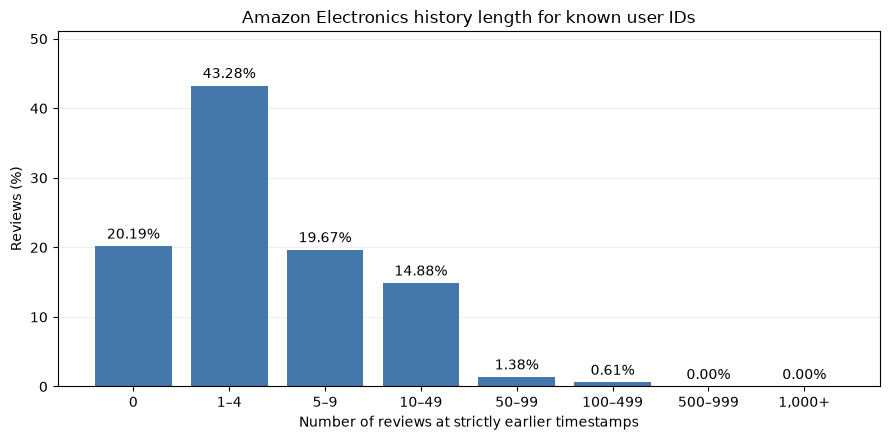

In [11]:
import matplotlib.pyplot as plt

bins = [-1, 0, 4, 9, 49, 99, 499, 999, float('inf')]
labels = ['0', '1–4', '5–9', '10–49', '50–99', '100–499', '500–999', '1,000+']
distribution = pd.cut(history_length, bins=bins, labels=labels).value_counts(sort=False)
percent = 100 * distribution / len(history_length)

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(labels, percent, color='#4477AA')
ax.bar_label(bars, labels=[f'{value:.2f}%' for value in percent], padding=3, fontsize=10)
ax.set(title='Amazon Electronics history length for known user IDs',
       xlabel='Number of reviews at strictly earlier timestamps',
       ylabel='Reviews (%)', ylim=(0, percent.max() * 1.18))
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

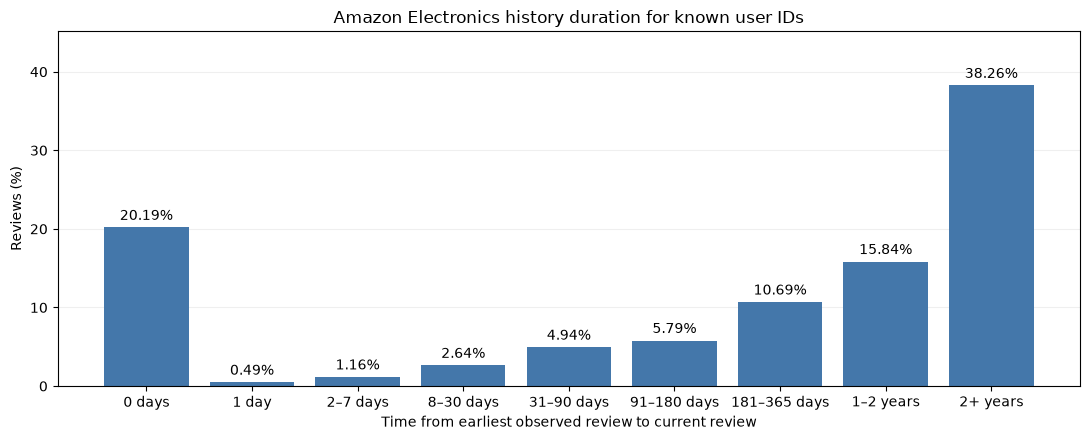

In [12]:
duration_hours = df.history_duration.dropna().dt.total_seconds() / 3600
bins = [-1, 0, 24, 168, 720, 2160, 4320, 8760, 17520, float('inf')]
labels = ['0 days', '1 day', '2–7 days', '8–30 days', '31–90 days', '91–180 days', '181–365 days', '1–2 years', '2+ years']
duration_distribution = pd.cut(duration_hours, bins=bins, labels=labels).value_counts(sort=False)
duration_percent = 100 * duration_distribution / len(duration_hours)

fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.bar(labels, duration_percent, color='#4477AA')
ax.bar_label(bars, labels=[f'{value:.2f}%' for value in duration_percent], padding=3, fontsize=10)
ax.set(title='Amazon Electronics history duration for known user IDs',
       xlabel='Time from earliest observed review to current review',
       ylabel='Reviews (%)', ylim=(0, duration_percent.max() * 1.18))
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

In [13]:
missing = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_%': 100 * df.isna().mean(),
})
missing.sort_values('missing_count', ascending=False).round(2)

,missing_count,missing_%
reviewerName,24854,1.47
reviewText,1071,0.06
asin,0,0.00
reviewerID,0,0.00
overall,0,0.00
summary,0,0.00
unixReviewTime,0,0.00
reviewTime,0,0.00
helpful_yes,0,0.00
helpful_total,0,0.00


In [5]:
outlier_features = ['helpful_yes', 'helpful_total']
# Anomaly flags retain the source values.
rows = []
for column in tqdm(outlier_features, desc='Numerical anomalies', leave=False):
    values = df[column].dropna()
    if values.empty:
        continue
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    if iqr <= 0:
        continue
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    anomalies = int(((values < lower) | (values > upper)).sum())
    rows.append({
        'feature': column, 'min': values.min(), 'max': values.max(),
        'lower bound': lower, 'upper bound': upper,
        'anomalies': anomalies, 'percent of anomalies': 100 * anomalies / len(values),
    })
if rows:
    print('Rule: 1.5 × IQR; percentages use non-missing values.')
    outliers = pd.DataFrame(rows).set_index('feature')
    display(outliers.style.format({
        'min': '{:,.2f}', 'max': '{:,.2f}', 'lower bound': '{:,.2f}',
        'upper bound': '{:,.2f}', 'anomalies': '{:,.0f}',
        'percent of anomalies': '{:.2f}',
    }))
elif outlier_features:
    print('No numerical features with a nonzero IQR.')
else:
    print('No raw numerical features to check.')

Rule: 1.5 × IQR; percentages use non-missing values.


,min,max,lower bound,upper bound,anomalies,percent of anomalies
feature,,,,,,
helpful_yes,0.00,"30,735.00",-1.50,2.50,"259,857",15.38
helpful_total,0.00,"31,453.00",-3.00,5.00,"175,288",10.38


In [14]:
import numpy as np
from itertools import combinations

matrix_features = ['overall', 'asin']

matrix_sample = df[matrix_features].sample(n=min(1_000_000, len(df)), random_state=42)
codes, margins = {}, {}
# Missing values form a category in this matrix.
for column in matrix_features:
    code, levels = pd.factorize(matrix_sample[column], sort=False, use_na_sentinel=False)
    assert (code >= 0).all()
    codes[column] = code.astype('int64')
    margins[column] = np.bincount(code)

# Bias correction: https://stats.lse.ac.uk/bergsma/pdf/cramerV3.pdf
def corrected_cramers_v(x, y, row_counts, column_counts):
    n, r, k = len(x), len(row_counts), len(column_counts)
    if min(r, k) <= 1:
        return 0.0
    pairs, observed = np.unique(x * k + y, return_counts=True)
    expected = row_counts[pairs // k] * column_counts[pairs % k] / n
    phi_squared = max(0.0, (np.sum(observed.astype(float) ** 2 / expected) - n) / n)
    corrected_phi = max(0.0, phi_squared - (r - 1) * (k - 1) / (n - 1))
    corrected_r = r - (r - 1) ** 2 / (n - 1)
    corrected_k = k - (k - 1) ** 2 / (n - 1)
    denominator = min(corrected_r - 1, corrected_k - 1)
    return float(np.clip(np.sqrt(corrected_phi / denominator), 0, 1)) if denominator > 0 else 0.0

association_matrix = pd.DataFrame(np.eye(len(matrix_features)), index=matrix_features, columns=matrix_features)
for x, y in tqdm(list(combinations(matrix_features, 2)), desc="Cramer's V", unit='pair', leave=False):
    value = corrected_cramers_v(codes[x], codes[y], margins[x], margins[y])
    association_matrix.loc[x, y] = association_matrix.loc[y, x] = value

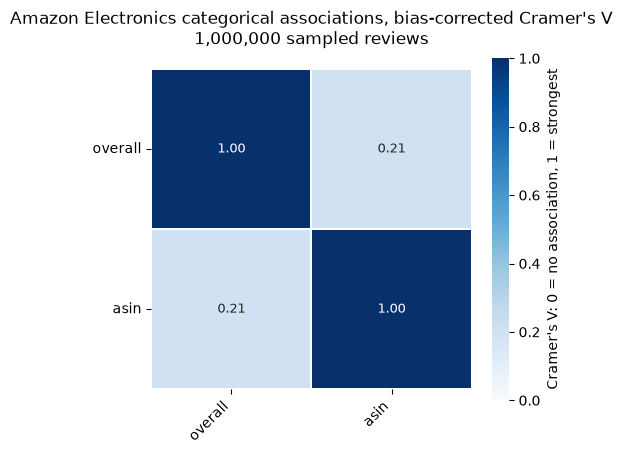

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(5.0, 4.5))
sns.heatmap(association_matrix, vmin=0, vmax=1, cmap='Blues', square=True,
            annot=True, fmt='.2f', annot_kws={'fontsize': 9}, linewidths=.25,
            cbar_kws={'label': "Cramer's V: 0 = no association, 1 = strongest"}, ax=ax)
ax.set_title(f"Amazon Electronics categorical associations, bias-corrected Cramer's V\n{len(matrix_sample):,} sampled reviews", pad=18)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_xlabel('')
ax.set_ylabel('')
fig.tight_layout()
plt.show()

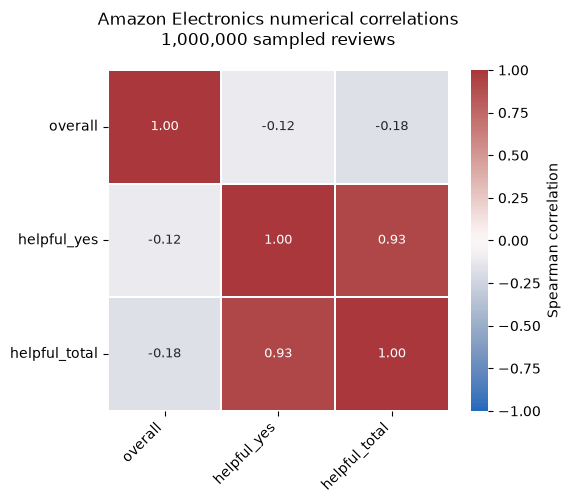

In [16]:
numerical_features = ['overall', 'helpful_yes', 'helpful_total']
numerical_sample = df[numerical_features].sample(n=min(1_000_000, len(df)), random_state=42)
numerical_correlation = numerical_sample.corr(method='spearman')

fig, ax = plt.subplots(figsize=(6.0, 5.0))
sns.heatmap(numerical_correlation, vmin=-1, vmax=1, center=0, cmap='vlag', square=True,
            annot=True, fmt='.2f', annot_kws={'fontsize': 9}, linewidths=.25,
            cbar_kws={'label': 'Spearman correlation'}, ax=ax)
ax.set_title(f'Amazon Electronics numerical correlations\n{len(numerical_sample):,} sampled reviews', pad=18)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_xlabel('')
ax.set_ylabel('')
fig.tight_layout()
plt.show()

# Taobao UserBehavior

Taobao UserBehavior contains **shopping actions**. Each row represents one user action on an item.

The columns describe:

- `user_id`, `item_id`, `category_id`: the user, item and category identifiers.
- `event`: the action, **`pv` for an item-page view, `buy` for purchase, `cart` for adding to cart, `fav` for favorite**.
- `timestamp`: when the action occurred.

In [2]:
import gc
from pathlib import Path
import pandas as pd
import pyarrow as pa
import pyarrow.csv as csv
from tqdm import tqdm

df = None
_ = gc.collect()
pa.default_memory_pool().release_unused()
pa.set_cpu_count(4)
pd.set_option('display.max_columns', None)
path = Path('data/taobao_userbehavior/raw/UserBehavior.csv.zip')

In [3]:
import zipfile

columns = ['user_id', 'item_id', 'category_id', 'event', 'timestamp']
column_types = {name: pa.int64() for name in ['user_id', 'item_id', 'category_id', 'timestamp']}
column_types['event'] = pa.string()
batches = []
with zipfile.ZipFile(path) as archive, archive.open('UserBehavior.csv') as source:
    reader = csv.open_csv(source,
        read_options=csv.ReadOptions(column_names=columns, block_size=32 << 20),
        convert_options=csv.ConvertOptions(column_types=column_types))
    with tqdm(total=100_150_807, unit='events', unit_scale=True, leave=False) as progress:
        for batch in reader:
            batches.append(batch)
            progress.update(batch.num_rows)
df = pa.Table.from_batches(batches).to_pandas(types_mapper=pd.ArrowDtype)
del batches, batch, reader

In [4]:
categorical_features = ['user_id', 'item_id', 'category_id', 'event']
assert df.event.isin(['pv', 'buy', 'cart', 'fav']).all()
df['timestamp'] = pd.to_datetime(df.timestamp, unit='s', utc=True)
for column in tqdm(categorical_features, desc='Convert categorical features', leave=False):
    df[column] = df[column].astype('category')

df.dtypes.to_frame('dtype')

,dtype
user_id,category
item_id,category
category_id,category
event,category
timestamp,"datetime64[us, UTC]"


In [5]:
df.shape

(100150807, 5)

In [6]:
df.head()

,user_id,item_id,category_id,event,timestamp
0,1,2268318,2520377,pv,2017-11-24 17:21:10+00:00
1,1,2333346,2520771,pv,2017-11-24 22:15:33+00:00
2,1,2576651,149192,pv,2017-11-25 01:21:25+00:00
3,1,3830808,4181361,pv,2017-11-25 07:04:53+00:00
4,1,4365585,2520377,pv,2017-11-25 07:49:06+00:00


In [7]:
df.describe(include='all')

,user_id,item_id,category_id,event,timestamp
count,100150807.0,100150807.0,100150807.0,100150807,100150807
unique,987994.0,4162024.0,9439.0,4,NaN
top,503757.0,812879.0,4756105.0,pv,NaN
freq,848.0,32633.0,4862531.0,89716264,NaN
mean,NaN,NaN,NaN,NaN,2017-11-29 10:27:56.872212+00:00
min,NaN,NaN,NaN,NaN,1902-05-07 22:32:46+00:00
25%,NaN,NaN,NaN,NaN,2017-11-27 05:50:43+00:00
50%,NaN,NaN,NaN,NaN,2017-11-29 14:09:56+00:00
75%,NaN,NaN,NaN,NaN,2017-12-02 01:44:42+00:00
max,NaN,NaN,NaN,NaN,2037-04-09 05:22:35+00:00


History is constructed from **earlier events with the same `user_id`**.

In [8]:
import random

counts = df.loc[df['user_id'].notna(), ['user_id', 'timestamp']].groupby('user_id', observed=True).agg(
    events=('timestamp', 'size'), distinct_times=('timestamp', 'nunique'))
eligible = counts.index[counts.events.between(3, 8) & counts.distinct_times.ge(2)]
user_id = random.choice(eligible)
events = df.loc[df['user_id'].eq(user_id)]
target = events.loc[events['timestamp'].gt(events['timestamp'].min())].sample(n=1)
history = events.loc[events['timestamp'].lt(target['timestamp'].iloc[0])].sort_values('timestamp')

example = pd.concat([history.assign(role='history'), target.assign(role='target')])
example = example[['role', 'timestamp', 'user_id', 'item_id', 'category_id', 'event']].copy()
example.reset_index(drop=True)

,role,timestamp,user_id,item_id,category_id,event
0,history,2017-11-25 07:26:47+00:00,761378,2754958,1973012,pv
1,history,2017-11-27 10:27:39+00:00,761378,1155350,1528133,pv
2,target,2017-11-30 01:04:44+00:00,761378,2016708,4792801,pv


In [9]:
known_user = df['user_id'].notna()
times = df.loc[known_user, 'timestamp']
earlier_count = times.groupby(df.loc[known_user, 'user_id'], sort=False, observed=True).rank(method='min') - 1
df['history_length'] = earlier_count.reindex(df.index).astype('int64[pyarrow]')
first_time = times.groupby(df.loc[known_user, 'user_id'], sort=False, observed=True).transform('min')
df['history_duration'] = (times - first_time).reindex(df.index)

In [10]:
history_length = df.history_length.dropna()
coverage = pd.Series({
    'Known user ID': int(known_user.sum()),
    'Unknown user ID': int((~known_user).sum()),
}, name='Events').to_frame()
coverage['Share (%)'] = (100 * coverage.Events / len(df)).round(2)
display(coverage)
def days_hours(value):
    if not isinstance(value, pd.Timedelta):
        return f'{value:,.0f}'
    total_hours = round(value.total_seconds() / 3600)
    days, hours = divmod(total_hours, 24)
    return f"{days} {'day' if days == 1 else 'days'} {hours} {'hour' if hours == 1 else 'hours'}"

quantiles = [.25, .5, .75, .9, .95, .99]
summary = history_length.describe(percentiles=quantiles).to_frame('history_length')
summary['history_duration, rounded to hours'] = df.history_duration.dropna().describe(percentiles=quantiles).map(days_hours)
summary.style.format({'history_length': '{:,.2f}'})

,Events,Share (%)
Known user ID,100150807,100.0
Unknown user ID,0,0.0


,history_length,"history_duration, rounded to hours"
count,"100,150,807.00","100,150,807"
mean,87.60,5 days 17 hours
std,84.35,203 days 7 hours
min,0.00,0 days 0 hours
25%,26.00,1 day 19 hours
50%,62.00,4 days 4 hours
75%,123.00,6 days 12 hours
90%,201.00,7 days 19 hours
95%,259.00,8 days 6 hours
99%,383.00,8 days 19 hours


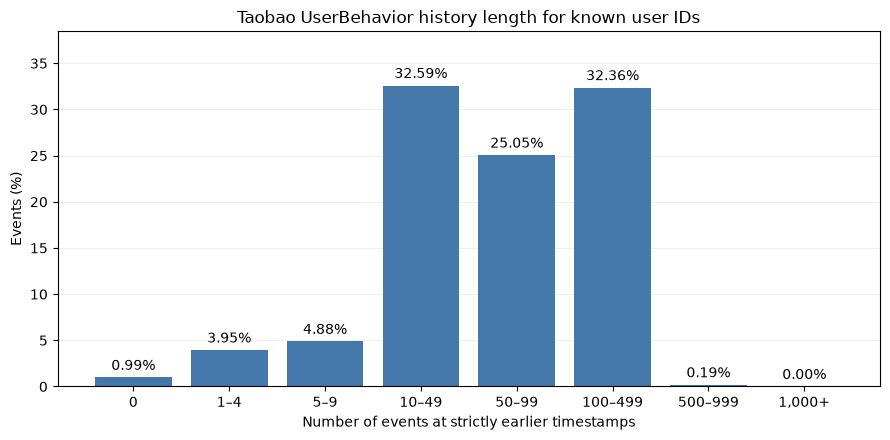

In [11]:
import matplotlib.pyplot as plt

bins = [-1, 0, 4, 9, 49, 99, 499, 999, float('inf')]
labels = ['0', '1–4', '5–9', '10–49', '50–99', '100–499', '500–999', '1,000+']
distribution = pd.cut(history_length, bins=bins, labels=labels).value_counts(sort=False)
percent = 100 * distribution / len(history_length)

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(labels, percent, color='#4477AA')
ax.bar_label(bars, labels=[f'{value:.2f}%' for value in percent], padding=3, fontsize=10)
ax.set(title='Taobao UserBehavior history length for known user IDs',
       xlabel='Number of events at strictly earlier timestamps',
       ylabel='Events (%)', ylim=(0, percent.max() * 1.18))
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

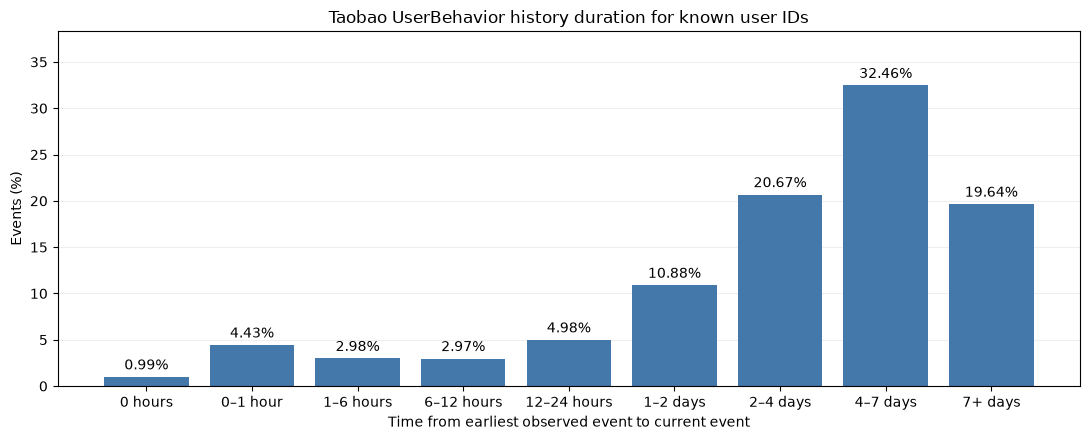

In [12]:
duration_hours = df.history_duration.dropna().dt.total_seconds() / 3600
bins = [-1, 0, 1, 6, 12, 24, 48, 96, 168, float('inf')]
labels = ['0 hours', '0–1 hour', '1–6 hours', '6–12 hours', '12–24 hours', '1–2 days', '2–4 days', '4–7 days', '7+ days']
duration_distribution = pd.cut(duration_hours, bins=bins, labels=labels).value_counts(sort=False)
duration_percent = 100 * duration_distribution / len(duration_hours)

fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.bar(labels, duration_percent, color='#4477AA')
ax.bar_label(bars, labels=[f'{value:.2f}%' for value in duration_percent], padding=3, fontsize=10)
ax.set(title='Taobao UserBehavior history duration for known user IDs',
       xlabel='Time from earliest observed event to current event',
       ylabel='Events (%)', ylim=(0, duration_percent.max() * 1.18))
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

In [13]:
missing = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_%': 100 * df.isna().mean(),
})
missing.sort_values('missing_count', ascending=False).round(2)

,missing_count,missing_%
user_id,0,0.0
item_id,0,0.0
category_id,0,0.0
event,0,0.0
timestamp,0,0.0
history_length,0,0.0
history_duration,0,0.0


No missing values

In [2]:
outlier_features = []
# Anomaly flags retain the source values.
rows = []
for column in tqdm(outlier_features, desc='Numerical anomalies', leave=False):
    values = df[column].dropna()
    if values.empty:
        continue
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    if iqr <= 0:
        continue
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    anomalies = int(((values < lower) | (values > upper)).sum())
    rows.append({
        'feature': column, 'min': values.min(), 'max': values.max(),
        'lower bound': lower, 'upper bound': upper,
        'anomalies': anomalies, 'percent of anomalies': 100 * anomalies / len(values),
    })
if rows:
    print('Rule: 1.5 × IQR; percentages use non-missing values.')
    outliers = pd.DataFrame(rows).set_index('feature')
    display(outliers.style.format({
        'min': '{:,.2f}', 'max': '{:,.2f}', 'lower bound': '{:,.2f}',
        'upper bound': '{:,.2f}', 'anomalies': '{:,.0f}',
        'percent of anomalies': '{:.2f}',
    }))
elif outlier_features:
    print('No numerical features with a nonzero IQR.')
else:
    print('No raw numerical features to check.')

No raw numerical features to check.


In [14]:
import numpy as np
from itertools import combinations

matrix_features = ['event', 'item_id', 'category_id']

matrix_sample = df[matrix_features].sample(n=min(1_000_000, len(df)), random_state=42)
codes, margins = {}, {}
# Missing values form a category in this matrix.
for column in matrix_features:
    code, levels = pd.factorize(matrix_sample[column], sort=False, use_na_sentinel=False)
    assert (code >= 0).all()
    codes[column] = code.astype('int64')
    margins[column] = np.bincount(code)

# Bias correction: https://stats.lse.ac.uk/bergsma/pdf/cramerV3.pdf
def corrected_cramers_v(x, y, row_counts, column_counts):
    n, r, k = len(x), len(row_counts), len(column_counts)
    if min(r, k) <= 1:
        return 0.0
    pairs, observed = np.unique(x * k + y, return_counts=True)
    expected = row_counts[pairs // k] * column_counts[pairs % k] / n
    phi_squared = max(0.0, (np.sum(observed.astype(float) ** 2 / expected) - n) / n)
    corrected_phi = max(0.0, phi_squared - (r - 1) * (k - 1) / (n - 1))
    corrected_r = r - (r - 1) ** 2 / (n - 1)
    corrected_k = k - (k - 1) ** 2 / (n - 1)
    denominator = min(corrected_r - 1, corrected_k - 1)
    return float(np.clip(np.sqrt(corrected_phi / denominator), 0, 1)) if denominator > 0 else 0.0

association_matrix = pd.DataFrame(np.eye(len(matrix_features)), index=matrix_features, columns=matrix_features)
for x, y in tqdm(list(combinations(matrix_features, 2)), desc="Cramer's V", unit='pair', leave=False):
    value = corrected_cramers_v(codes[x], codes[y], margins[x], margins[y])
    association_matrix.loc[x, y] = association_matrix.loc[y, x] = value

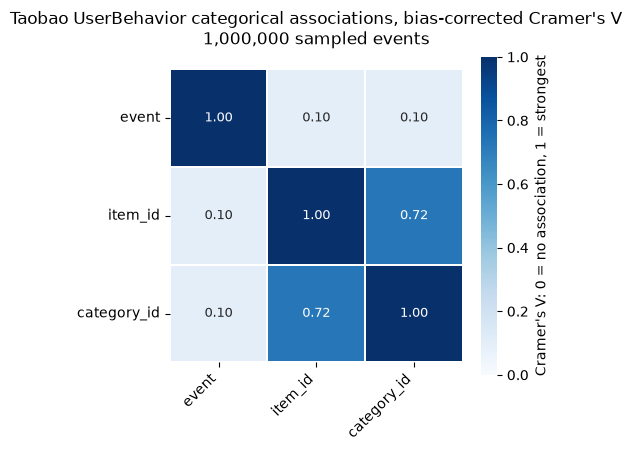

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(5.0, 4.5))
sns.heatmap(association_matrix, vmin=0, vmax=1, cmap='Blues', square=True,
            annot=True, fmt='.2f', annot_kws={'fontsize': 9}, linewidths=.25,
            cbar_kws={'label': "Cramer's V: 0 = no association, 1 = strongest"}, ax=ax)
ax.set_title(f"Taobao UserBehavior categorical associations, bias-corrected Cramer's V\n{len(matrix_sample):,} sampled events", pad=18)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_xlabel('')
ax.set_ylabel('')
fig.tight_layout()
plt.show()

# Taobao Ad Click

Taobao Ad Click is an advertising dataset used to **predict whether an ad impression will receive a click**. Each row represents one logged impression, joined to its user and ad attributes.

The columns describe:

- `user`, `adgroup_id`: the user and ad identifiers.
- `clk`: the target, **1 for clicked, 0 for not clicked**. `nonclk` is its complement.
- `time_stamp`, `pid`: the impression time and placement.
- `cate_id`, `campaign_id`, `customer`, `brand`, `price`: the ad category, campaign, advertiser, brand and price.
- `cms_segid`, `cms_group_id`, `final_gender_code`, `age_level`, `pvalue_level`, `shopping_level`, `occupation`, `new_user_class_level`: categorical user attributes.

In [2]:
import gc
from pathlib import Path
import pandas as pd
import pyarrow as pa
import pyarrow.csv as csv
from tqdm import tqdm

df = None
_ = gc.collect()
pa.default_memory_pool().release_unused()
pa.set_cpu_count(4)
pd.set_option('display.max_columns', None)
path = Path('data/taobao_ad_click/raw')

In [3]:
column_types = {
    'user': pa.string(), 'time_stamp': pa.int64(), 'adgroup_id': pa.string(),
    'pid': pa.string(), 'nonclk': pa.int8(), 'clk': pa.int8(),
}
reader = csv.open_csv(path / 'raw_sample.csv', read_options=csv.ReadOptions(block_size=32 << 20),
                      convert_options=csv.ConvertOptions(column_types=column_types))
batches = []
with tqdm(total=26_557_961, unit='rows', unit_scale=True, leave=False) as progress:
    for batch in reader:
        batches.append(batch)
        progress.update(batch.num_rows)
df = pa.Table.from_batches(batches).to_pandas(types_mapper=pd.ArrowDtype)
del batches, batch, reader

user_columns = ['userid', 'cms_segid', 'cms_group_id', 'final_gender_code', 'age_level',
                'pvalue_level', 'shopping_level', 'occupation', 'new_user_class_level ']
users = csv.read_csv(path / 'user_profile.csv', convert_options=csv.ConvertOptions(
    column_types={name: pa.string() for name in user_columns}, null_values=['', 'NULL'], strings_can_be_null=True)
).to_pandas(types_mapper=pd.ArrowDtype)
users.columns = users.columns.str.strip()
users = users.rename(columns={'userid': 'user'})
ad_types = {name: pa.string() for name in ['adgroup_id', 'cate_id', 'campaign_id', 'customer', 'brand']}
ad_types['price'] = pa.float64()
ads = csv.read_csv(path / 'ad_feature.csv', convert_options=csv.ConvertOptions(
    column_types=ad_types, null_values=['', 'NULL'], strings_can_be_null=True)
).to_pandas(types_mapper=pd.ArrowDtype)
for attributes, key in tqdm([(users, 'user'), (ads, 'adgroup_id')], desc='Join attributes', leave=False):
    df = df.merge(attributes, on=key, how='left', validate='many_to_one', sort=False)
del users, ads, attributes

In [4]:
categorical_features = [name for name in df.columns if name not in ['time_stamp', 'clk', 'nonclk', 'price']]
assert df.clk.isin([0, 1]).all() and df.nonclk.isin([0, 1]).all()
assert (df.clk + df.nonclk).eq(1).all()
df['clk'] = df.clk.astype('uint8[pyarrow]')
df['nonclk'] = df.nonclk.astype('uint8[pyarrow]')
df['time_stamp'] = pd.to_datetime(df.time_stamp, unit='s', utc=True)
for column in tqdm(categorical_features, desc='Convert categorical features', leave=False):
    df[column] = df[column].astype('category')

df.dtypes.to_frame('dtype')

,dtype
user,category
time_stamp,"datetime64[us, UTC]"
adgroup_id,category
pid,category
nonclk,uint8[pyarrow]
clk,uint8[pyarrow]
cms_segid,category
cms_group_id,category
final_gender_code,category
age_level,category


In [5]:
df.shape

(26557961, 19)

In [6]:
df.head()

,user,time_stamp,adgroup_id,pid,nonclk,clk,cms_segid,cms_group_id,final_gender_code,age_level,pvalue_level,shopping_level,occupation,new_user_class_level,cate_id,campaign_id,customer,brand,price
0,581738,2017-05-07 06:14:04+00:00,1,430548_1007,1,0,0,8,1,2,<NA>,3,0,<NA>,9025,108570,1337,20169,17.0
1,449818,2017-05-13 01:26:18+00:00,3,430548_1007,1,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,5998,224368,30507,<NA>,1.0
2,914836,2017-05-13 04:47:59+00:00,4,430548_1007,1,0,0,5,2,5,<NA>,3,0,2,7958,385883,39662,216840,85.0
3,914836,2017-05-13 04:50:29+00:00,5,430548_1007,1,0,0,5,2,5,<NA>,3,0,2,7958,385883,39662,216840,60.0
4,399907,2017-05-09 04:09:18+00:00,8,430548_1007,1,0,0,5,2,5,<NA>,3,0,2,1626,388290,42349,241359,63.0


In [7]:
df.describe(include='all')

,user,time_stamp,adgroup_id,pid,nonclk,clk,cms_segid,cms_group_id,final_gender_code,age_level,pvalue_level,shopping_level,occupation,new_user_class_level,cate_id,campaign_id,customer,brand,price
count,26557961,26557961,26557961,26557961,26557961.0,26557961.0,25029435,25029435,25029435,25029435,12005163,25029435,25029435,18333132,26557961,26557961,26557961,18266267,26557961.0
unique,1141729,NaN,846811,2,<NA>,<NA>,97,13,2,7,3,3,2,4,6769,423436,255875,99814,<NA>
top,658554,NaN,710164,430548_1007,<NA>,<NA>,0,3,2,3,2,3,0,2,6261,359520,28529,234846,<NA>
freq,3756,NaN,70929,16472898,<NA>,<NA>,14491053,5697945,18148469,7573614,6991303,21316498,23665487,8125425,2925127,128484,260575,229621,<NA>
mean,NaN,2017-05-09 18:33:18.141513+00:00,NaN,NaN,0.948563,0.051437,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,747.33907
min,NaN,2017-05-05 16:00:00+00:00,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.01
25%,NaN,2017-05-07 15:33:51+00:00,NaN,NaN,1.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,86.0
50%,NaN,2017-05-09 15:48:12+00:00,NaN,NaN,1.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,168.0
75%,NaN,2017-05-11 15:22:16+00:00,NaN,NaN,1.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,328.0
max,NaN,2017-05-13 15:59:46+00:00,NaN,NaN,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,99999999.0


History is constructed from **earlier impressions with the same `user`**.

In [8]:
import random

counts = df.loc[df['user'].notna(), ['user', 'time_stamp']].groupby('user', observed=True).agg(
    events=('time_stamp', 'size'), distinct_times=('time_stamp', 'nunique'))
eligible = counts.index[counts.events.between(3, 8) & counts.distinct_times.ge(2)]
user_id = random.choice(eligible)
events = df.loc[df['user'].eq(user_id)]
target = events.loc[events['time_stamp'].gt(events['time_stamp'].min())].sample(n=1)
history = events.loc[events['time_stamp'].lt(target['time_stamp'].iloc[0])].sort_values('time_stamp')

example = pd.concat([history.assign(role='history'), target.assign(role='target')])
example = example[['role', 'time_stamp', 'user', 'adgroup_id', 'pid', 'clk']].copy()
example.reset_index(drop=True)

,role,time_stamp,user,adgroup_id,pid,clk
0,history,2017-05-10 12:10:07+00:00,523871,433165,430548_1007,0
1,history,2017-05-10 12:10:07+00:00,523871,225826,430548_1007,0
2,history,2017-05-10 12:10:07+00:00,523871,590154,430548_1007,0
3,target,2017-05-10 14:14:40+00:00,523871,608450,430548_1007,0


In [9]:
known_user = df['user'].notna()
times = df.loc[known_user, 'time_stamp']
earlier_count = times.groupby(df.loc[known_user, 'user'], sort=False, observed=True).rank(method='min') - 1
df['history_length'] = earlier_count.reindex(df.index).astype('int64[pyarrow]')
first_time = times.groupby(df.loc[known_user, 'user'], sort=False, observed=True).transform('min')
df['history_duration'] = (times - first_time).reindex(df.index)

In [10]:
history_length = df.history_length.dropna()
coverage = pd.Series({
    'Known user ID': int(known_user.sum()),
    'Unknown user ID': int((~known_user).sum()),
}, name='Impressions').to_frame()
coverage['Share (%)'] = (100 * coverage.Impressions / len(df)).round(2)
display(coverage)
def days_hours(value):
    if not isinstance(value, pd.Timedelta):
        return f'{value:,.0f}'
    total_hours = round(value.total_seconds() / 3600)
    days, hours = divmod(total_hours, 24)
    return f"{days} {'day' if days == 1 else 'days'} {hours} {'hour' if hours == 1 else 'hours'}"

quantiles = [.25, .5, .75, .9, .95, .99]
summary = history_length.describe(percentiles=quantiles).to_frame('history_length')
summary['history_duration, rounded to hours'] = df.history_duration.dropna().describe(percentiles=quantiles).map(days_hours)
summary.style.format({'history_length': '{:,.2f}'})

,Impressions,Share (%)
Known user ID,26557961,100.0
Unknown user ID,0,0.0


,history_length,"history_duration, rounded to hours"
count,"26,557,961.00","26,557,961"
mean,100.60,2 days 18 hours
std,194.26,2 days 9 hours
min,0.00,0 days 0 hours
25%,6.00,0 days 9 hours
50%,26.00,2 days 9 hours
75%,97.00,4 days 17 hours
90%,298.00,6 days 6 hours
95%,479.00,6 days 23 hours
99%,941.00,7 days 12 hours


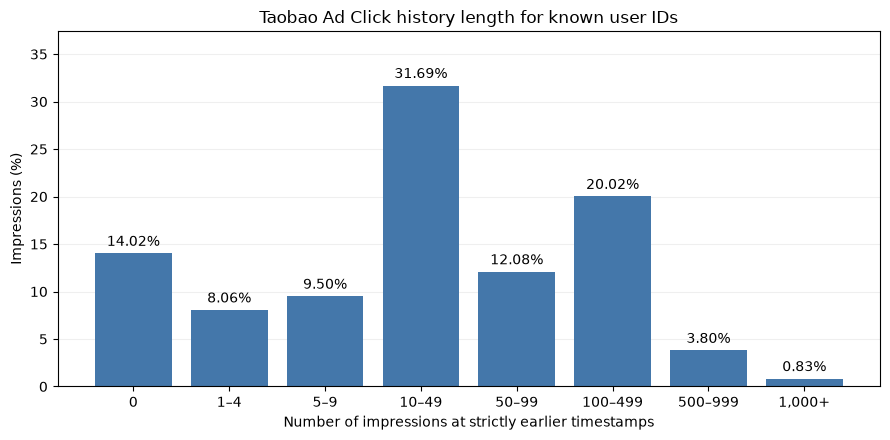

In [11]:
import matplotlib.pyplot as plt

bins = [-1, 0, 4, 9, 49, 99, 499, 999, float('inf')]
labels = ['0', '1–4', '5–9', '10–49', '50–99', '100–499', '500–999', '1,000+']
distribution = pd.cut(history_length, bins=bins, labels=labels).value_counts(sort=False)
percent = 100 * distribution / len(history_length)

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(labels, percent, color='#4477AA')
ax.bar_label(bars, labels=[f'{value:.2f}%' for value in percent], padding=3, fontsize=10)
ax.set(title='Taobao Ad Click history length for known user IDs',
       xlabel='Number of impressions at strictly earlier timestamps',
       ylabel='Impressions (%)', ylim=(0, percent.max() * 1.18))
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

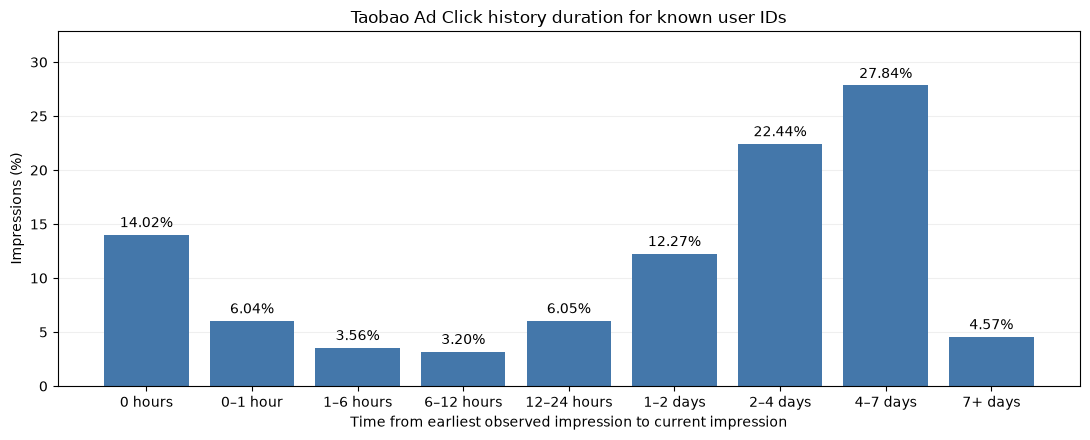

In [12]:
duration_hours = df.history_duration.dropna().dt.total_seconds() / 3600
bins = [-1, 0, 1, 6, 12, 24, 48, 96, 168, float('inf')]
labels = ['0 hours', '0–1 hour', '1–6 hours', '6–12 hours', '12–24 hours', '1–2 days', '2–4 days', '4–7 days', '7+ days']
duration_distribution = pd.cut(duration_hours, bins=bins, labels=labels).value_counts(sort=False)
duration_percent = 100 * duration_distribution / len(duration_hours)

fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.bar(labels, duration_percent, color='#4477AA')
ax.bar_label(bars, labels=[f'{value:.2f}%' for value in duration_percent], padding=3, fontsize=10)
ax.set(title='Taobao Ad Click history duration for known user IDs',
       xlabel='Time from earliest observed impression to current impression',
       ylabel='Impressions (%)', ylim=(0, duration_percent.max() * 1.18))
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

In [13]:
missing = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_%': 100 * df.isna().mean(),
})
missing.sort_values('missing_count', ascending=False).round(2)

,missing_count,missing_%
pvalue_level,14552798,54.80
brand,8291694,31.22
new_user_class_level,8224829,30.97
cms_segid,1528526,5.76
shopping_level,1528526,5.76
occupation,1528526,5.76
age_level,1528526,5.76
final_gender_code,1528526,5.76
cms_group_id,1528526,5.76
user,0,0.00


In [5]:
outlier_features = ['price']
# Anomaly flags retain the source values.
rows = []
for column in tqdm(outlier_features, desc='Numerical anomalies', leave=False):
    values = df[column].dropna()
    if values.empty:
        continue
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    if iqr <= 0:
        continue
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    anomalies = int(((values < lower) | (values > upper)).sum())
    rows.append({
        'feature': column, 'min': values.min(), 'max': values.max(),
        'lower bound': lower, 'upper bound': upper,
        'anomalies': anomalies, 'percent of anomalies': 100 * anomalies / len(values),
    })
if rows:
    print('Rule: 1.5 × IQR; percentages use non-missing values.')
    outliers = pd.DataFrame(rows).set_index('feature')
    display(outliers.style.format({
        'min': '{:,.2f}', 'max': '{:,.2f}', 'lower bound': '{:,.2f}',
        'upper bound': '{:,.2f}', 'anomalies': '{:,.0f}',
        'percent of anomalies': '{:.2f}',
    }))
elif outlier_features:
    print('No numerical features with a nonzero IQR.')
else:
    print('No raw numerical features to check.')

Rule: 1.5 × IQR; percentages use non-missing values.


,min,max,lower bound,upper bound,anomalies,percent of anomalies
feature,,,,,,
price,0.01,"99,999,999.00",-277.00,691.00,"2,646,433",9.96


In [14]:
import numpy as np
from itertools import combinations

matrix_features = ['clk', 'adgroup_id', 'pid', 'cate_id', 'campaign_id', 'customer', 'brand', 'cms_segid', 'cms_group_id', 'final_gender_code', 'age_level', 'pvalue_level', 'shopping_level', 'occupation', 'new_user_class_level']

matrix_sample = df[matrix_features].sample(n=min(1_000_000, len(df)), random_state=42)
codes, margins = {}, {}
# Missing values form a category in this matrix.
for column in matrix_features:
    code, levels = pd.factorize(matrix_sample[column], sort=False, use_na_sentinel=False)
    assert (code >= 0).all()
    codes[column] = code.astype('int64')
    margins[column] = np.bincount(code)

# Bias correction: https://stats.lse.ac.uk/bergsma/pdf/cramerV3.pdf
def corrected_cramers_v(x, y, row_counts, column_counts):
    n, r, k = len(x), len(row_counts), len(column_counts)
    if min(r, k) <= 1:
        return 0.0
    pairs, observed = np.unique(x * k + y, return_counts=True)
    expected = row_counts[pairs // k] * column_counts[pairs % k] / n
    phi_squared = max(0.0, (np.sum(observed.astype(float) ** 2 / expected) - n) / n)
    corrected_phi = max(0.0, phi_squared - (r - 1) * (k - 1) / (n - 1))
    corrected_r = r - (r - 1) ** 2 / (n - 1)
    corrected_k = k - (k - 1) ** 2 / (n - 1)
    denominator = min(corrected_r - 1, corrected_k - 1)
    return float(np.clip(np.sqrt(corrected_phi / denominator), 0, 1)) if denominator > 0 else 0.0

association_matrix = pd.DataFrame(np.eye(len(matrix_features)), index=matrix_features, columns=matrix_features)
for x, y in tqdm(list(combinations(matrix_features, 2)), desc="Cramer's V", unit='pair', leave=False):
    value = corrected_cramers_v(codes[x], codes[y], margins[x], margins[y])
    association_matrix.loc[x, y] = association_matrix.loc[y, x] = value

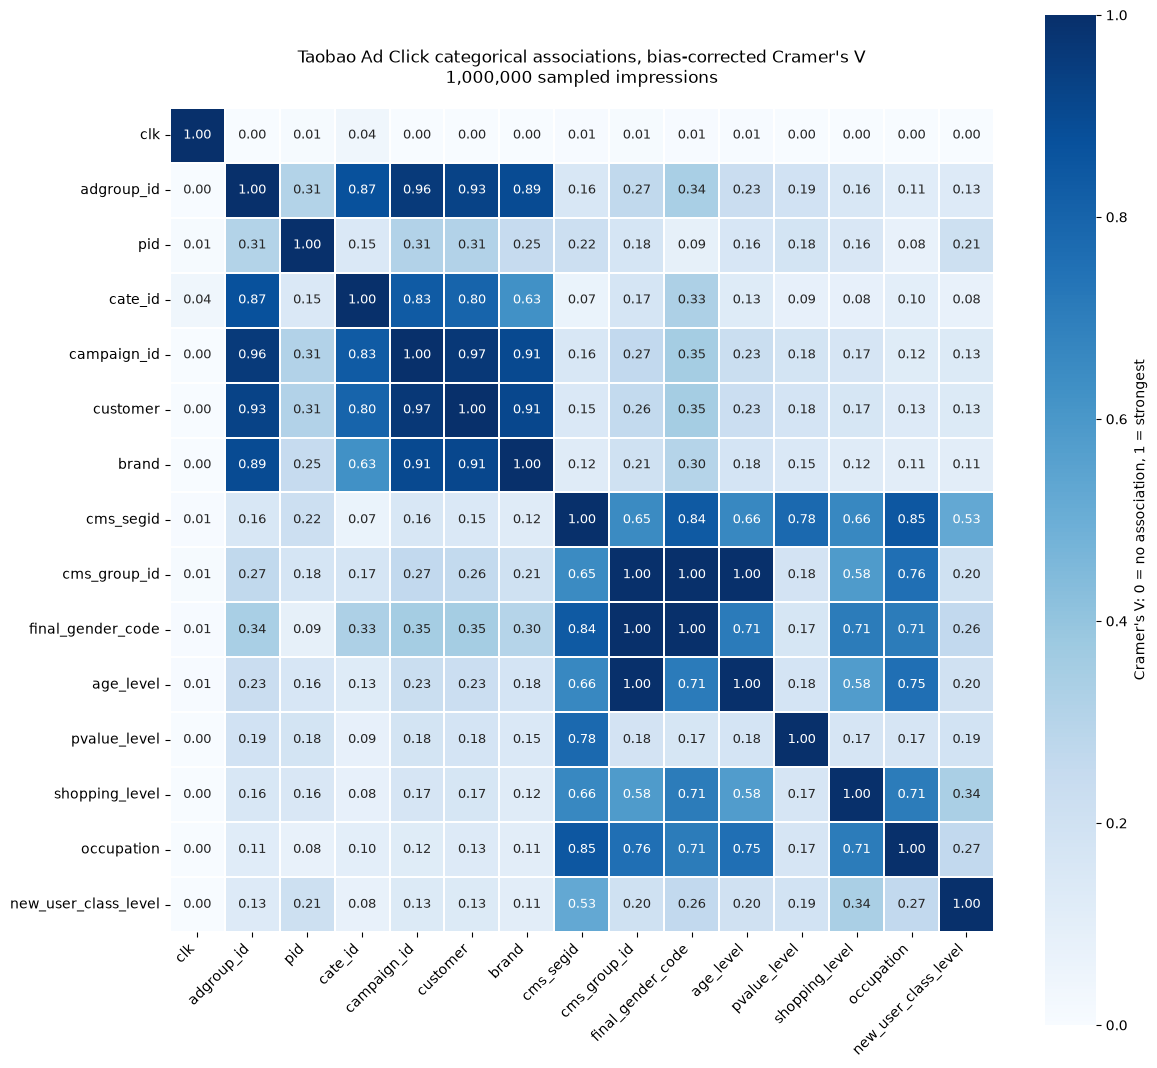

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(12.2, 11.2))
sns.heatmap(association_matrix, vmin=0, vmax=1, cmap='Blues', square=True,
            annot=True, fmt='.2f', annot_kws={'fontsize': 9}, linewidths=.25,
            cbar_kws={'label': "Cramer's V: 0 = no association, 1 = strongest"}, ax=ax)
ax.set_title(f"Taobao Ad Click categorical associations, bias-corrected Cramer's V\n{len(matrix_sample):,} sampled impressions", pad=18)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_xlabel('')
ax.set_ylabel('')
fig.tight_layout()
plt.show()

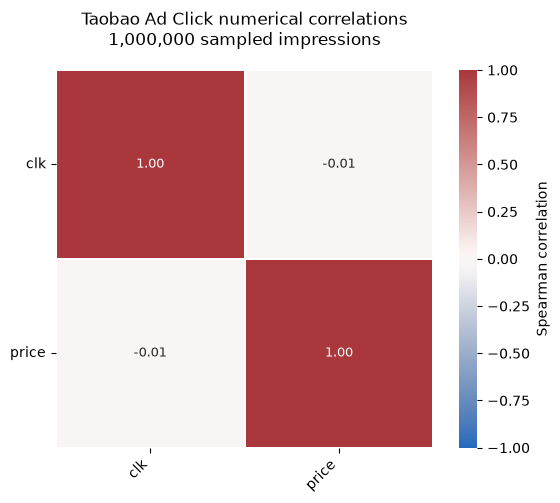

In [16]:
numerical_features = ['clk', 'price']
numerical_sample = df[numerical_features].sample(n=min(1_000_000, len(df)), random_state=42)
numerical_correlation = numerical_sample.corr(method='spearman')

fig, ax = plt.subplots(figsize=(6.0, 5.0))
sns.heatmap(numerical_correlation, vmin=-1, vmax=1, center=0, cmap='vlag', square=True,
            annot=True, fmt='.2f', annot_kws={'fontsize': 9}, linewidths=.25,
            cbar_kws={'label': 'Spearman correlation'}, ax=ax)
ax.set_title(f'Taobao Ad Click numerical correlations\n{len(numerical_sample):,} sampled impressions', pad=18)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_xlabel('')
ax.set_ylabel('')
fig.tight_layout()
plt.show()

# KuaiRand-1K

KuaiRand-1K contains **video interaction logs and user feedback**. Each row represents one logged interaction.

The columns describe:

- `user_id`, `video_id`: the user and video identifiers.
- `time_ms`, `date`, `hourmin`: the interaction time.
- `is_click`: click feedback in the two-column interface, valid-play feedback in the single-column interface.
- `is_like`, `is_follow`, `is_comment`, `is_forward`, `is_hate`, `long_view`, `is_profile_enter`: other feedback signals.
- `play_time_ms`, `duration_ms`, `profile_stay_time`, `comment_stay_time`: video and viewing durations.
- `is_rand`, `tab`: random-exposure flag and interface.

In [2]:
import gc
from pathlib import Path
import pandas as pd
import pyarrow as pa
import pyarrow.csv as csv
from tqdm import tqdm

df = None
_ = gc.collect()
pa.default_memory_pool().release_unused()
pa.set_cpu_count(4)
pd.set_option('display.max_columns', None)
path = Path('data/kuairand_1k/raw')

import hashlib
import requests

path.mkdir(parents=True, exist_ok=True)
archive_path = path / 'KuaiRand-1K.tar.gz'
source_url = 'https://zenodo.org/records/10439422/files/KuaiRand-1K.tar.gz?download=1'
if not archive_path.exists():
    temporary = archive_path.with_suffix(archive_path.suffix + '.part')
    with requests.get(source_url, stream=True, timeout=(30, 120)) as response:
        response.raise_for_status()
        total = int(response.headers.get('Content-Length', 0)) or None
        with temporary.open('wb') as target, tqdm(total=total, unit='B', unit_scale=True, desc='Download', leave=False) as progress:
            for chunk in response.iter_content(4 << 20):
                if chunk:
                    target.write(chunk)
                    progress.update(len(chunk))
    temporary.replace(archive_path)
digest = hashlib.new('md5')
with archive_path.open('rb') as source, tqdm(total=archive_path.stat().st_size, unit='B', unit_scale=True, desc='Verify archive', leave=False) as progress:
    for chunk in iter(lambda: source.read(8 << 20), b''):
        digest.update(chunk)
        progress.update(len(chunk))
assert digest.hexdigest() == '6b0b9c8222d67fcd4c676218edca3f1f'
del chunk

In [3]:
import tarfile
import shutil

log_names = ['log_standard_4_08_to_4_21_1k.csv', 'log_standard_4_22_to_5_08_1k.csv',
             'log_random_4_22_to_5_08_1k.csv']
if not all((path / name).exists() for name in log_names):
    with tarfile.open(archive_path, 'r:gz') as archive, tqdm(total=len(log_names), desc='Extract logs', leave=False) as progress:
        for member in archive:
            name = Path(member.name).name
            if name in log_names:
                with archive.extractfile(member) as source, (path / name).open('wb') as target:
                    shutil.copyfileobj(source, target, length=8 << 20)
                progress.update(1)

binary_features = ['is_click', 'is_like', 'is_follow', 'is_comment', 'is_forward',
                   'is_hate', 'long_view', 'is_profile_enter', 'is_rand']
column_types = {name: pa.int8() for name in binary_features}
column_types.update({name: pa.int64() for name in [
    'user_id', 'video_id', 'date', 'hourmin', 'time_ms', 'play_time_ms',
    'duration_ms', 'profile_stay_time', 'comment_stay_time', 'tab']})
batches, source_rows = [], {}
with tqdm(desc='Load interaction logs', unit='rows', unit_scale=True, leave=False) as progress:
    for name in log_names:
        source_rows[name] = 0
        reader = csv.open_csv(path / name, read_options=csv.ReadOptions(block_size=32 << 20),
                              convert_options=csv.ConvertOptions(column_types=column_types))
        for batch in reader:
            batches.append(batch)
            source_rows[name] += batch.num_rows
            progress.update(batch.num_rows)
df = pa.Table.from_batches(batches).to_pandas(types_mapper=pd.ArrowDtype)
del batches, batch, reader

In [4]:
categorical_features = ['user_id', 'video_id', 'tab']
df['time_ms'] = pd.to_datetime(df.time_ms, unit='ms', utc=True)
df['date'] = pd.to_datetime(df.date.astype('string'), format='%Y%m%d')
df['hourmin'] = df.hourmin.astype('string[pyarrow]').str.zfill(4)
for column in binary_features:
    assert df[column].isin([0, 1]).all()
    df[column] = df[column].astype('uint8[pyarrow]')
for column in tqdm(categorical_features, desc='Convert categorical features', leave=False):
    df[column] = df[column].astype('category')

df.dtypes.to_frame('dtype')

,dtype
user_id,category
video_id,category
date,datetime64[us]
hourmin,string
time_ms,"datetime64[us, UTC]"
is_click,uint8[pyarrow]
is_like,uint8[pyarrow]
is_follow,uint8[pyarrow]
is_comment,uint8[pyarrow]
is_forward,uint8[pyarrow]


In [5]:
df.shape

(11756073, 19)

In [6]:
df.head()

,user_id,video_id,date,hourmin,time_ms,is_click,is_like,is_follow,is_comment,is_forward,is_hate,long_view,play_time_ms,duration_ms,profile_stay_time,comment_stay_time,is_profile_enter,is_rand,tab
0,0,4354972,2022-04-09,0900,2022-04-09 01:33:02.289+00:00,0,0,0,0,0,0,0,0,70100,0,0,0,0,0
1,0,1329429,2022-04-09,0900,2022-04-09 01:33:02.289+00:00,0,0,0,0,0,0,0,0,51422,0,0,0,0,0
2,0,346081,2022-04-09,0900,2022-04-09 01:33:02.289+00:00,0,0,0,0,0,0,0,0,11696,0,0,0,0,0
3,0,2058916,2022-04-09,0900,2022-04-09 01:33:02.289+00:00,0,0,0,0,0,0,0,0,66433,0,0,0,0,0
4,0,2528540,2022-04-09,0900,2022-04-09 01:33:02.289+00:00,1,0,0,0,0,0,0,5332,11450,0,0,0,0,0


In [7]:
df.describe(include='all')

,user_id,video_id,date,hourmin,time_ms,is_click,is_like,is_follow,is_comment,is_forward,is_hate,long_view,play_time_ms,duration_ms,profile_stay_time,comment_stay_time,is_profile_enter,is_rand,tab
count,11756073.0,11756073.0,11756073,11756073,11756073,11756073.0,11756073.0,11756073.0,11756073.0,11756073.0,11756073.0,11756073.0,11756073.0,11756073.0,11756073.0,11756073.0,11756073.0,11756073.0,11756073.0
unique,1000.0,4371868.0,NaN,24,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,15.0
top,879.0,26075.0,NaN,2100,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,1.0
freq,127647.0,585.0,NaN,797194,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,7760237.0
mean,NaN,NaN,2022-04-23 09:41:00.169786,NaN,2022-04-23 16:16:54.842851+00:00,0.37745,0.015573,0.00097,0.002649,0.000784,0.000926,0.261404,14760.752195,72302.210122,6.799016,489.982014,0.017853,0.00366,NaN
min,NaN,NaN,2022-04-08 00:00:00,NaN,2022-04-07 14:00:03.236000+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN
25%,NaN,NaN,2022-04-16 00:00:00,NaN,2022-04-15 19:02:59.390000+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1015.0,10383.0,0.0,0.0,0.0,0.0,NaN
50%,NaN,NaN,2022-04-24 00:00:00,NaN,2022-04-23 20:45:32.995000+00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3015.0,29200.0,0.0,0.0,0.0,0.0,NaN
75%,NaN,NaN,2022-05-01 00:00:00,NaN,2022-05-01 13:30:40.082000+00:00,1.0,0.0,0.0,0.0,0.0,0.0,1.0,12592.0,95900.0,0.0,0.0,0.0,0.0,NaN
max,NaN,NaN,2022-05-08 00:00:00,NaN,2022-05-08 15:52:09.022000+00:00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1529347.0,16513080.0,300000.0,300000.0,1.0,1.0,NaN


History is constructed from **earlier interactions with the same `user_id`**.

In [8]:
import random

counts = df.loc[df['user_id'].notna(), ['user_id', 'time_ms']].groupby('user_id', observed=True).agg(
    events=('time_ms', 'size'), distinct_times=('time_ms', 'nunique'))
eligible = counts.index[counts.events.ge(4) & counts.distinct_times.ge(2)]
for user_id in random.sample(list(eligible), len(eligible)):
    events = df.loc[df['user_id'].eq(user_id)]
    candidates = events.loc[events['time_ms'].rank(method='min').between(4, 9)]
    if len(candidates):
        target = candidates.sample(n=1)
        break
else:
    raise ValueError('No short history example is available.')
history = events.loc[events['time_ms'].lt(target['time_ms'].iloc[0])].sort_values('time_ms')

example = pd.concat([history.assign(role='history'), target.assign(role='target')])
example = example[['role', 'time_ms', 'user_id', 'video_id', 'is_click', 'tab']].copy()
example.reset_index(drop=True)

,role,time_ms,user_id,video_id,is_click,tab
0,history,2022-04-07 15:54:22.954+00:00,245,1468716,0,1
1,history,2022-04-07 15:54:22.954+00:00,245,1733132,1,1
2,history,2022-04-07 15:54:22.954+00:00,245,656243,0,1
3,history,2022-04-07 15:54:22.954+00:00,245,1416757,1,1
4,history,2022-04-07 15:54:22.954+00:00,245,2082090,1,1
5,history,2022-04-07 15:54:22.954+00:00,245,1260939,1,1
6,history,2022-04-07 15:54:22.954+00:00,245,1603869,1,1
7,target,2022-04-07 15:57:10.008+00:00,245,328516,0,1


In [9]:
known_user = df['user_id'].notna()
times = df.loc[known_user, 'time_ms']
earlier_count = times.groupby(df.loc[known_user, 'user_id'], sort=False, observed=True).rank(method='min') - 1
df['history_length'] = earlier_count.reindex(df.index).astype('int64[pyarrow]')
first_time = times.groupby(df.loc[known_user, 'user_id'], sort=False, observed=True).transform('min')
df['history_duration'] = (times - first_time).reindex(df.index)

In [10]:
history_length = df.history_length.dropna()
coverage = pd.Series({
    'Known user ID': int(known_user.sum()),
    'Unknown user ID': int((~known_user).sum()),
}, name='Interactions').to_frame()
coverage['Share (%)'] = (100 * coverage.Interactions / len(df)).round(2)
display(coverage)
def days_hours(value):
    if not isinstance(value, pd.Timedelta):
        return f'{value:,.0f}'
    total_hours = round(value.total_seconds() / 3600)
    days, hours = divmod(total_hours, 24)
    return f"{days} {'day' if days == 1 else 'days'} {hours} {'hour' if hours == 1 else 'hours'}"

quantiles = [.25, .5, .75, .9, .95, .99]
summary = history_length.describe(percentiles=quantiles).to_frame('history_length')
summary['history_duration, rounded to hours'] = df.history_duration.dropna().describe(percentiles=quantiles).map(days_hours)
summary.style.format({'history_length': '{:,.2f}'})

,Interactions,Share (%)
Known user ID,11756073,100.0
Unknown user ID,0,0.0


,history_length,"history_duration, rounded to hours"
count,"11,756,073.00","11,756,073"
mean,"11,934.70",15 days 12 hours
std,"14,085.05",9 days 1 hour
min,0.00,0 days 0 hours
25%,"3,174.00",7 days 14 hours
50%,"7,418.00",15 days 15 hours
75%,"15,236.00",23 days 9 hours
90%,"27,460.00",27 days 18 hours
95%,"38,943.00",29 days 7 hours
99%,"68,910.00",30 days 13 hours


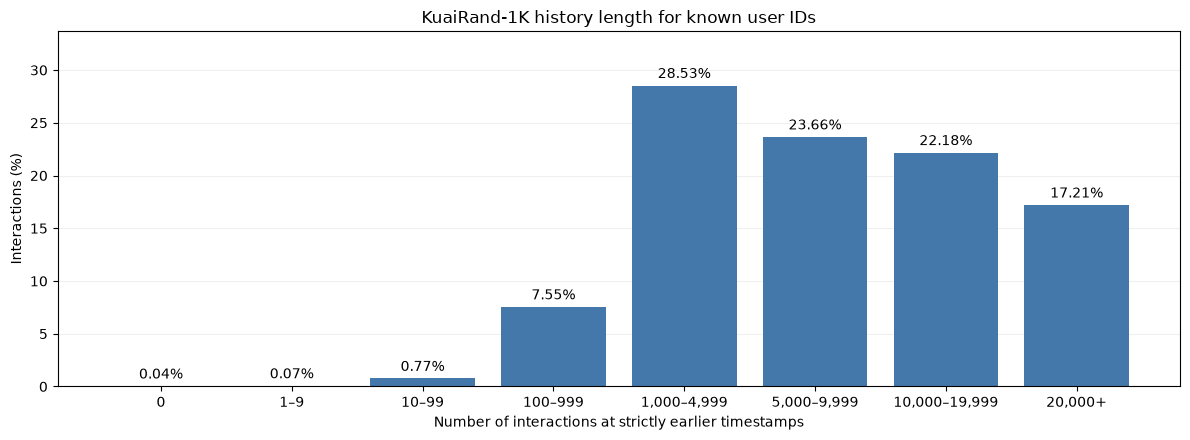

In [11]:
import matplotlib.pyplot as plt

bins = [-1, 0, 9, 99, 999, 4999, 9999, 19999, float('inf')]
labels = ['0', '1–9', '10–99', '100–999', '1,000–4,999', '5,000–9,999', '10,000–19,999', '20,000+']
distribution = pd.cut(history_length, bins=bins, labels=labels).value_counts(sort=False)
percent = 100 * distribution / len(history_length)

fig, ax = plt.subplots(figsize=(12, 4.5))
bars = ax.bar(labels, percent, color='#4477AA')
ax.bar_label(bars, labels=[f'{value:.2f}%' for value in percent], padding=3, fontsize=10)
ax.set(title='KuaiRand-1K history length for known user IDs',
       xlabel='Number of interactions at strictly earlier timestamps',
       ylabel='Interactions (%)', ylim=(0, percent.max() * 1.18))
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

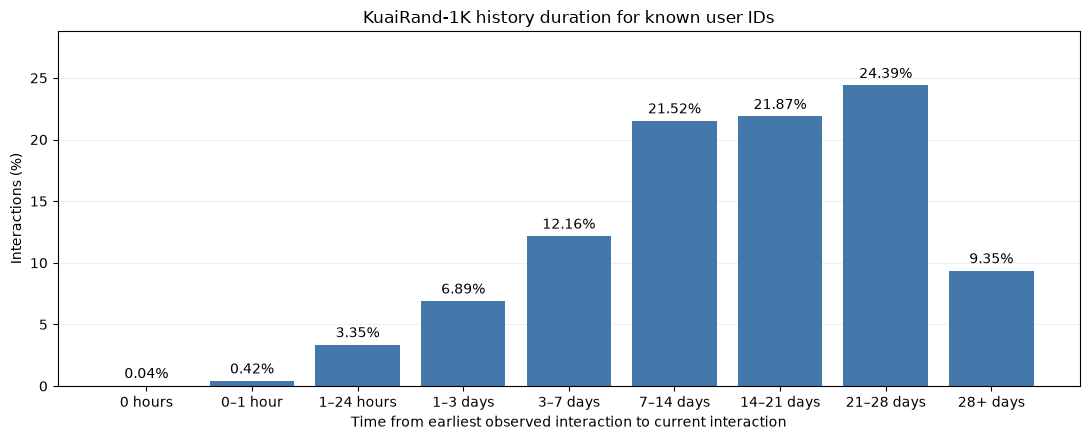

In [12]:
duration_hours = df.history_duration.dropna().dt.total_seconds() / 3600
bins = [-1, 0, 1, 24, 72, 168, 336, 504, 672, float('inf')]
labels = ['0 hours', '0–1 hour', '1–24 hours', '1–3 days', '3–7 days', '7–14 days', '14–21 days', '21–28 days', '28+ days']
duration_distribution = pd.cut(duration_hours, bins=bins, labels=labels).value_counts(sort=False)
duration_percent = 100 * duration_distribution / len(duration_hours)

fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.bar(labels, duration_percent, color='#4477AA')
ax.bar_label(bars, labels=[f'{value:.2f}%' for value in duration_percent], padding=3, fontsize=10)
ax.set(title='KuaiRand-1K history duration for known user IDs',
       xlabel='Time from earliest observed interaction to current interaction',
       ylabel='Interactions (%)', ylim=(0, duration_percent.max() * 1.18))
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

In [13]:
missing = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_%': 100 * df.isna().mean(),
})
missing.sort_values('missing_count', ascending=False).round(2)

,missing_count,missing_%
user_id,0,0.0
video_id,0,0.0
date,0,0.0
hourmin,0,0.0
time_ms,0,0.0
is_click,0,0.0
is_like,0,0.0
is_follow,0,0.0
is_comment,0,0.0
is_forward,0,0.0


In [14]:
outlier_features = ['play_time_ms', 'duration_ms', 'profile_stay_time', 'comment_stay_time']
# Anomaly flags retain the source values.
rows = []
for column in tqdm(outlier_features, desc='Numerical anomalies', leave=False):
    values = df[column].dropna()
    if values.empty:
        continue
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    if iqr <= 0:
        continue
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    anomalies = int(((values < lower) | (values > upper)).sum())
    rows.append({
        'feature': column, 'min': values.min(), 'max': values.max(),
        'lower bound': lower, 'upper bound': upper,
        'anomalies': anomalies, 'percent of anomalies': 100 * anomalies / len(values),
    })
if rows:
    print('Rule: 1.5 × IQR; percentages use non-missing values.')
    outliers = pd.DataFrame(rows).set_index('feature')
    display(outliers.style.format({
        'min': '{:,.2f}', 'max': '{:,.2f}', 'lower bound': '{:,.2f}',
        'upper bound': '{:,.2f}', 'anomalies': '{:,.0f}',
        'percent of anomalies': '{:.2f}',
    }))
elif outlier_features:
    print('No numerical features with a nonzero IQR.')
else:
    print('No raw numerical features to check.')

Rule: 1.5 × IQR; percentages use non-missing values.


,min,max,lower bound,upper bound,anomalies,percent of anomalies
feature,,,,,,
play_time_ms,0.00,"1,529,347.00","-16,350.50","29,957.50","1,495,263",12.72
duration_ms,0.00,"16,513,080.00","-117,892.50","224,175.50","899,332",7.65


In [15]:
import numpy as np
from itertools import combinations

matrix_features = ['is_click', 'video_id', 'tab', 'is_rand', 'is_like', 'is_follow', 'is_comment', 'is_forward', 'is_hate', 'long_view', 'is_profile_enter']

matrix_sample = df[matrix_features].sample(n=min(1_000_000, len(df)), random_state=42)
codes, margins = {}, {}
# Missing values form a category in this matrix.
for column in matrix_features:
    code, levels = pd.factorize(matrix_sample[column], sort=False, use_na_sentinel=False)
    assert (code >= 0).all()
    codes[column] = code.astype('int64')
    margins[column] = np.bincount(code)

# Bias correction: https://stats.lse.ac.uk/bergsma/pdf/cramerV3.pdf
def corrected_cramers_v(x, y, row_counts, column_counts):
    n, r, k = len(x), len(row_counts), len(column_counts)
    if min(r, k) <= 1:
        return 0.0
    pairs, observed = np.unique(x * k + y, return_counts=True)
    expected = row_counts[pairs // k] * column_counts[pairs % k] / n
    phi_squared = max(0.0, (np.sum(observed.astype(float) ** 2 / expected) - n) / n)
    corrected_phi = max(0.0, phi_squared - (r - 1) * (k - 1) / (n - 1))
    corrected_r = r - (r - 1) ** 2 / (n - 1)
    corrected_k = k - (k - 1) ** 2 / (n - 1)
    denominator = min(corrected_r - 1, corrected_k - 1)
    return float(np.clip(np.sqrt(corrected_phi / denominator), 0, 1)) if denominator > 0 else 0.0

association_matrix = pd.DataFrame(np.eye(len(matrix_features)), index=matrix_features, columns=matrix_features)
for x, y in tqdm(list(combinations(matrix_features, 2)), desc="Cramer's V", unit='pair', leave=False):
    value = corrected_cramers_v(codes[x], codes[y], margins[x], margins[y])
    association_matrix.loc[x, y] = association_matrix.loc[y, x] = value

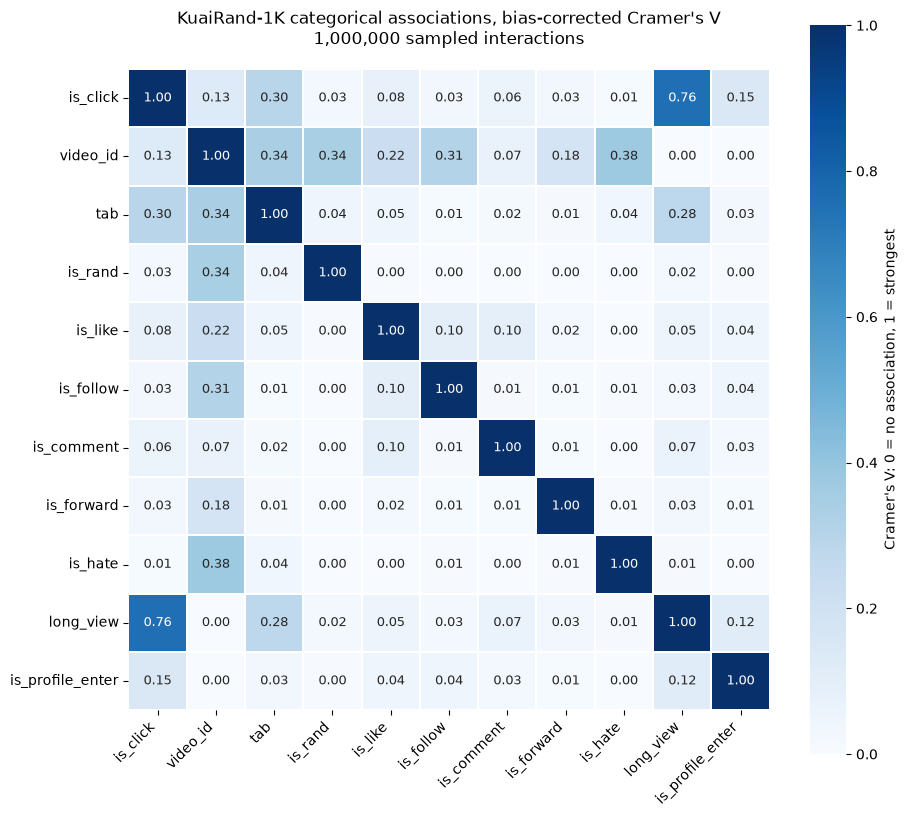

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(9.5, 8.5))
sns.heatmap(association_matrix, vmin=0, vmax=1, cmap='Blues', square=True,
            annot=True, fmt='.2f', annot_kws={'fontsize': 9}, linewidths=.25,
            cbar_kws={'label': "Cramer's V: 0 = no association, 1 = strongest"}, ax=ax)
ax.set_title(f"KuaiRand-1K categorical associations, bias-corrected Cramer's V\n{len(matrix_sample):,} sampled interactions", pad=18)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_xlabel('')
ax.set_ylabel('')
fig.tight_layout()
plt.show()

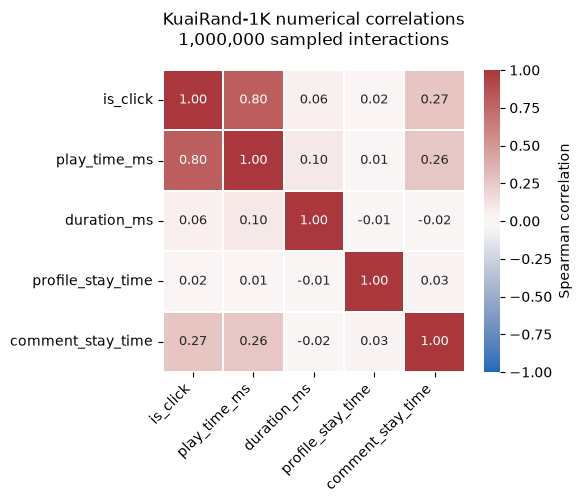

In [17]:
numerical_features = ['is_click', 'play_time_ms', 'duration_ms', 'profile_stay_time', 'comment_stay_time']
numerical_sample = df[numerical_features].sample(n=min(1_000_000, len(df)), random_state=42)
numerical_correlation = numerical_sample.corr(method='spearman')

fig, ax = plt.subplots(figsize=(6.0, 5.0))
sns.heatmap(numerical_correlation, vmin=-1, vmax=1, center=0, cmap='vlag', square=True,
            annot=True, fmt='.2f', annot_kws={'fontsize': 9}, linewidths=.25,
            cbar_kws={'label': 'Spearman correlation'}, ax=ax)
ax.set_title(f'KuaiRand-1K numerical correlations\n{len(numerical_sample):,} sampled interactions', pad=18)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_xlabel('')
ax.set_ylabel('')
fig.tight_layout()
plt.show()

# Tmall

Tmall contains **shopping action logs**. Each row represents one user action on an item, joined to the user's profile.

The columns describe:

- `user_id`, `item_id`, `cat_id`, `seller_id`, `brand_id`: the user, item, category, seller and brand identifiers.
- `action_type`: **0 for click, 1 for cart, 2 for purchase, 3 for favorite**.
- `time_stamp`: month and day. `event_day` represents the day-of-year offset because the year is unspecified.
- `age_range`, `gender`: categorical user attributes.

In [2]:
import gc
from pathlib import Path
import pandas as pd
import pyarrow as pa
import pyarrow.csv as csv
from tqdm import tqdm

df = None
_ = gc.collect()
pa.default_memory_pool().release_unused()
pa.set_cpu_count(4)
pd.set_option('display.max_columns', None)
path = Path('data/tmall/raw')

import hashlib
import requests

path.mkdir(parents=True, exist_ok=True)
archive_path = path / 'data_format1.zip'
source_url = 'https://media.githubusercontent.com/media/zeronow/Repeat-Buyers-Prediction/master/Data/data_format1.zip'
if not archive_path.exists():
    temporary = archive_path.with_suffix(archive_path.suffix + '.part')
    with requests.get(source_url, stream=True, timeout=(30, 120)) as response:
        response.raise_for_status()
        total = int(response.headers.get('Content-Length', 0)) or None
        with temporary.open('wb') as target, tqdm(total=total, unit='B', unit_scale=True, desc='Download', leave=False) as progress:
            for chunk in response.iter_content(4 << 20):
                if chunk:
                    target.write(chunk)
                    progress.update(len(chunk))
    temporary.replace(archive_path)
digest = hashlib.new('sha256')
with archive_path.open('rb') as source, tqdm(total=archive_path.stat().st_size, unit='B', unit_scale=True, desc='Verify archive', leave=False) as progress:
    for chunk in iter(lambda: source.read(8 << 20), b''):
        digest.update(chunk)
        progress.update(len(chunk))
assert digest.hexdigest() == '0ba29c89bb2bd89e701ec3f751d08ca7cd325aface14a5550e2be6904245f45f'
del chunk

In [3]:
import zipfile

column_types = {name: pa.int64() for name in ['user_id', 'item_id', 'cat_id', 'seller_id', 'brand_id', 'action_type']}
column_types['time_stamp'] = pa.string()
batches = []
with zipfile.ZipFile(archive_path) as archive:
    with archive.open('data_format1/user_log_format1.csv') as source:
        reader = csv.open_csv(source, read_options=csv.ReadOptions(block_size=32 << 20),
                              convert_options=csv.ConvertOptions(column_types=column_types))
        with tqdm(total=54_925_330, unit='rows', unit_scale=True, leave=False) as progress:
            for batch in reader:
                batches.append(batch)
                progress.update(batch.num_rows)
    df = pa.Table.from_batches(batches).to_pandas(types_mapper=pd.ArrowDtype)
    del batches, batch, reader
    with archive.open('data_format1/user_info_format1.csv') as source:
        users = csv.read_csv(source, convert_options=csv.ConvertOptions(column_types={
            'user_id': pa.int64(), 'age_range': pa.int64(), 'gender': pa.int64()})).to_pandas(types_mapper=pd.ArrowDtype)
df = df.merge(users, on='user_id', how='left', validate='many_to_one', sort=False)
del users

In [4]:
categorical_features = ['user_id', 'item_id', 'cat_id', 'seller_id', 'brand_id', 'action_type', 'age_range', 'gender']
assert df.action_type.isin([0, 1, 2, 3]).all()
df['time_stamp'] = df.time_stamp.astype('string[pyarrow]').str.zfill(4)
date_codes = df.time_stamp.drop_duplicates()
parsed_days = pd.to_datetime(date_codes, format='%m%d').dt.day_of_year - 1
day_lookup = dict(zip(date_codes, pd.to_timedelta(parsed_days, unit='D')))
df['event_day'] = df.time_stamp.map(day_lookup).astype('timedelta64[ns]')
for column in tqdm(categorical_features, desc='Convert categorical features', leave=False):
    df[column] = df[column].astype('category')

df.dtypes.to_frame('dtype')

,dtype
user_id,category
item_id,category
cat_id,category
seller_id,category
brand_id,category
time_stamp,string
action_type,category
age_range,category
gender,category
event_day,timedelta64[ns]


In [5]:
df.shape

(54925330, 10)

In [6]:
df.head()

,user_id,item_id,cat_id,seller_id,brand_id,time_stamp,action_type,age_range,gender,event_day
0,328862,323294,833,2882,2661,0829,0,6,1,240 days
1,328862,844400,1271,2882,2661,0829,0,6,1,240 days
2,328862,575153,1271,2882,2661,0829,0,6,1,240 days
3,328862,996875,1271,2882,2661,0829,0,6,1,240 days
4,328862,1086186,1271,1253,1049,0829,0,6,1,240 days


In [7]:
df.describe(include='all')

,user_id,item_id,cat_id,seller_id,brand_id,time_stamp,action_type,age_range,gender,event_day
count,54925330.0,54925330.0,54925330.0,54925330.0,54834315.0,54925330,54925330.0,54797107.0,54503835.0,54925330
unique,424170.0,1090390.0,1658.0,4995.0,8443.0,186,4.0,9.0,3.0,NaN
top,254263.0,67897.0,662.0,3760.0,3738.0,1111,0.0,3.0,0.0,NaN
freq,14468.0,345905.0,4339025.0,743217.0,763345.0,10582633,48550713.0,14848637.0,40313178.0,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,258 days 16:08:03.230422084
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,57 days 22:50:58.502345979
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,130 days 00:00:00
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,210 days 00:00:00
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,282 days 00:00:00
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,312 days 00:00:00


History is constructed from **earlier actions with the same `user_id`**.

In [8]:
import random

counts = df.loc[df['user_id'].notna(), ['user_id', 'event_day']].groupby('user_id', observed=True).agg(
    events=('event_day', 'size'), distinct_times=('event_day', 'nunique'))
eligible = counts.index[counts.events.ge(4) & counts.distinct_times.ge(2)]
for user_id in random.sample(list(eligible), len(eligible)):
    events = df.loc[df['user_id'].eq(user_id)]
    candidates = events.loc[events['event_day'].rank(method='min').between(4, 9)]
    if len(candidates):
        target = candidates.sample(n=1)
        break
else:
    raise ValueError('No short history example is available.')
history = events.loc[events['event_day'].lt(target['event_day'].iloc[0])].sort_values('event_day')

example = pd.concat([history.assign(role='history'), target.assign(role='target')])
example = example[['role', 'time_stamp', 'user_id', 'item_id', 'action_type']].copy()
example.reset_index(drop=True)

,role,time_stamp,user_id,item_id,action_type
0,history,0611,111052,893999,0
1,history,0611,111052,893999,0
2,history,0611,111052,893999,2
3,history,0611,111052,893999,0
4,history,0611,111052,893999,0
5,target,0619,111052,984494,0


In [9]:
known_user = df['user_id'].notna()
times = df.loc[known_user, 'event_day']
earlier_count = times.groupby(df.loc[known_user, 'user_id'], sort=False, observed=True).rank(method='min') - 1
df['history_length'] = earlier_count.reindex(df.index).astype('int64[pyarrow]')
first_time = times.groupby(df.loc[known_user, 'user_id'], sort=False, observed=True).transform('min')
df['history_duration'] = (times - first_time).reindex(df.index)

In [10]:
history_length = df.history_length.dropna()
coverage = pd.Series({
    'Known user ID': int(known_user.sum()),
    'Unknown user ID': int((~known_user).sum()),
}, name='Actions').to_frame()
coverage['Share (%)'] = (100 * coverage.Actions / len(df)).round(2)
display(coverage)
def days_hours(value):
    if not isinstance(value, pd.Timedelta):
        return f'{value:,.0f}'
    total_hours = round(value.total_seconds() / 3600)
    days, hours = divmod(total_hours, 24)
    return f"{days} {'day' if days == 1 else 'days'} {hours} {'hour' if hours == 1 else 'hours'}"

quantiles = [.25, .5, .75, .9, .95, .99]
summary = history_length.describe(percentiles=quantiles).to_frame('history_length')
summary['history_duration, rounded to hours'] = df.history_duration.dropna().describe(percentiles=quantiles).map(days_hours)
summary.style.format({'history_length': '{:,.2f}'})

,Actions,Share (%)
Known user ID,54925330,100.0
Unknown user ID,0,0.0


,history_length,"history_duration, rounded to hours"
count,"54,925,330.00","54,925,330"
mean,181.28,105 days 8 hours
std,362.38,59 days 12 hours
min,0.00,0 days 0 hours
25%,26.00,50 days 0 hours
50%,78.00,117 days 0 hours
75%,199.00,162 days 0 hours
90%,432.00,174 days 0 hours
95%,674.00,179 days 0 hours
99%,"1,549.00",183 days 0 hours


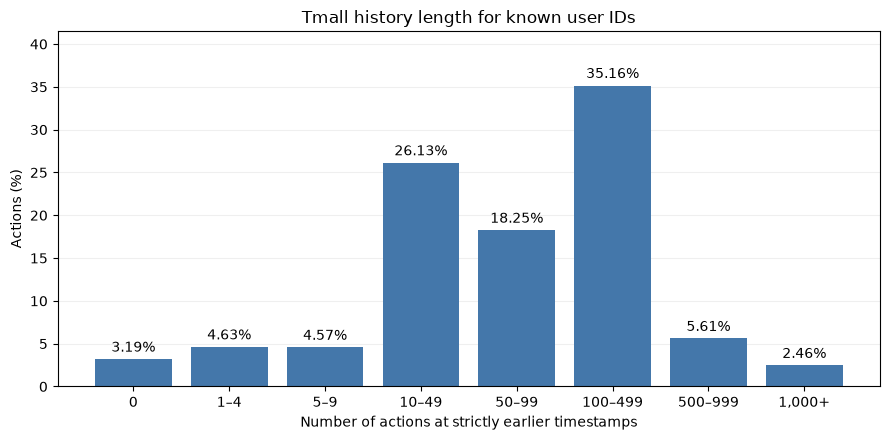

In [11]:
import matplotlib.pyplot as plt

bins = [-1, 0, 4, 9, 49, 99, 499, 999, float('inf')]
labels = ['0', '1–4', '5–9', '10–49', '50–99', '100–499', '500–999', '1,000+']
distribution = pd.cut(history_length, bins=bins, labels=labels).value_counts(sort=False)
percent = 100 * distribution / len(history_length)

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(labels, percent, color='#4477AA')
ax.bar_label(bars, labels=[f'{value:.2f}%' for value in percent], padding=3, fontsize=10)
ax.set(title='Tmall history length for known user IDs',
       xlabel='Number of actions at strictly earlier timestamps',
       ylabel='Actions (%)', ylim=(0, percent.max() * 1.18))
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

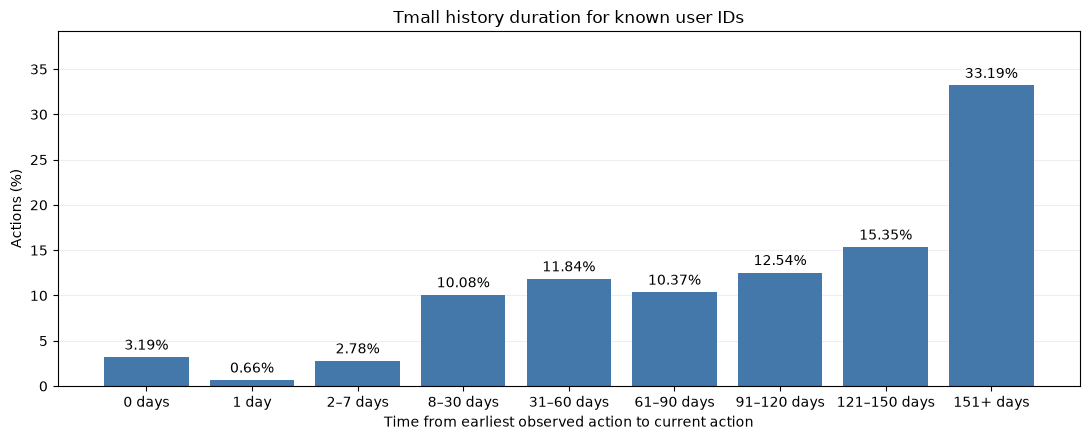

In [12]:
duration_hours = df.history_duration.dropna().dt.total_seconds() / 3600
bins = [-1, 0, 24, 168, 720, 1440, 2160, 2880, 3600, float('inf')]
labels = ['0 days', '1 day', '2–7 days', '8–30 days', '31–60 days', '61–90 days', '91–120 days', '121–150 days', '151+ days']
duration_distribution = pd.cut(duration_hours, bins=bins, labels=labels).value_counts(sort=False)
duration_percent = 100 * duration_distribution / len(duration_hours)

fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.bar(labels, duration_percent, color='#4477AA')
ax.bar_label(bars, labels=[f'{value:.2f}%' for value in duration_percent], padding=3, fontsize=10)
ax.set(title='Tmall history duration for known user IDs',
       xlabel='Time from earliest observed action to current action',
       ylabel='Actions (%)', ylim=(0, duration_percent.max() * 1.18))
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

In [13]:
missing = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_%': 100 * df.isna().mean(),
})
missing.sort_values('missing_count', ascending=False).round(2)

,missing_count,missing_%
gender,421495,0.77
age_range,128223,0.23
brand_id,91015,0.17
user_id,0,0.00
seller_id,0,0.00
cat_id,0,0.00
item_id,0,0.00
time_stamp,0,0.00
action_type,0,0.00
event_day,0,0.00


In [14]:
outlier_features = []
# Anomaly flags retain the source values.
rows = []
for column in tqdm(outlier_features, desc='Numerical anomalies', leave=False):
    values = df[column].dropna()
    if values.empty:
        continue
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    if iqr <= 0:
        continue
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    anomalies = int(((values < lower) | (values > upper)).sum())
    rows.append({
        'feature': column, 'min': values.min(), 'max': values.max(),
        'lower bound': lower, 'upper bound': upper,
        'anomalies': anomalies, 'percent of anomalies': 100 * anomalies / len(values),
    })
if rows:
    print('Rule: 1.5 × IQR; percentages use non-missing values.')
    outliers = pd.DataFrame(rows).set_index('feature')
    display(outliers.style.format({
        'min': '{:,.2f}', 'max': '{:,.2f}', 'lower bound': '{:,.2f}',
        'upper bound': '{:,.2f}', 'anomalies': '{:,.0f}',
        'percent of anomalies': '{:.2f}',
    }))
elif outlier_features:
    print('No numerical features with a nonzero IQR.')
else:
    print('No raw numerical features to check.')

No raw numerical features to check.


In [15]:
import numpy as np
from itertools import combinations

matrix_features = ['action_type', 'item_id', 'cat_id', 'seller_id', 'brand_id', 'age_range', 'gender']

matrix_sample = df[matrix_features].sample(n=min(1_000_000, len(df)), random_state=42)
codes, margins = {}, {}
# Missing values form a category in this matrix.
for column in matrix_features:
    code, levels = pd.factorize(matrix_sample[column], sort=False, use_na_sentinel=False)
    assert (code >= 0).all()
    codes[column] = code.astype('int64')
    margins[column] = np.bincount(code)

# Bias correction: https://stats.lse.ac.uk/bergsma/pdf/cramerV3.pdf
def corrected_cramers_v(x, y, row_counts, column_counts):
    n, r, k = len(x), len(row_counts), len(column_counts)
    if min(r, k) <= 1:
        return 0.0
    pairs, observed = np.unique(x * k + y, return_counts=True)
    expected = row_counts[pairs // k] * column_counts[pairs % k] / n
    phi_squared = max(0.0, (np.sum(observed.astype(float) ** 2 / expected) - n) / n)
    corrected_phi = max(0.0, phi_squared - (r - 1) * (k - 1) / (n - 1))
    corrected_r = r - (r - 1) ** 2 / (n - 1)
    corrected_k = k - (k - 1) ** 2 / (n - 1)
    denominator = min(corrected_r - 1, corrected_k - 1)
    return float(np.clip(np.sqrt(corrected_phi / denominator), 0, 1)) if denominator > 0 else 0.0

association_matrix = pd.DataFrame(np.eye(len(matrix_features)), index=matrix_features, columns=matrix_features)
for x, y in tqdm(list(combinations(matrix_features, 2)), desc="Cramer's V", unit='pair', leave=False):
    value = corrected_cramers_v(codes[x], codes[y], margins[x], margins[y])
    association_matrix.loc[x, y] = association_matrix.loc[y, x] = value

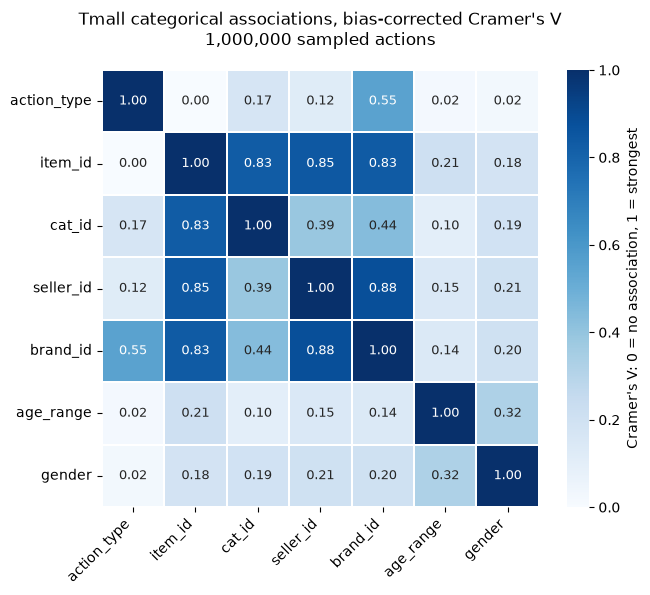

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(6.8, 5.8))
sns.heatmap(association_matrix, vmin=0, vmax=1, cmap='Blues', square=True,
            annot=True, fmt='.2f', annot_kws={'fontsize': 9}, linewidths=.25,
            cbar_kws={'label': "Cramer's V: 0 = no association, 1 = strongest"}, ax=ax)
ax.set_title(f"Tmall categorical associations, bias-corrected Cramer's V\n{len(matrix_sample):,} sampled actions", pad=18)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_xlabel('')
ax.set_ylabel('')
fig.tight_layout()
plt.show()

# KuaiVideo

KuaiVideo contains **video impressions and feedback**. Each row represents one logged impression in the released train or test file.

The columns describe:

- `user_id`, `item_id`: the user and video identifiers.
- `is_click`: the target, **1 for clicked, 0 for not clicked**.
- `is_like`, `is_follow`: like and follow feedback.
- `timestamp`: anonymized time preserving event order.
- `pos_items`, `neg_items`: supplied positive and negative item histories, separated by `^`, each capped at 100 entries.

In [2]:
import gc
from pathlib import Path
import pandas as pd
import pyarrow as pa
import pyarrow.csv as csv
from tqdm import tqdm

df = None
_ = gc.collect()
pa.default_memory_pool().release_unused()
pa.set_cpu_count(4)
pd.set_option('display.max_columns', None)
path = Path('data/kuaivideo/raw')

import hashlib
import requests

path.mkdir(parents=True, exist_ok=True)
archive_path = path / 'KuaiVideo_x1.zip'
source_url = 'https://huggingface.co/datasets/reczoo/KuaiVideo_x1/resolve/main/KuaiVideo_x1.zip?download=true'
if not archive_path.exists():
    temporary = archive_path.with_suffix(archive_path.suffix + '.part')
    with requests.get(source_url, stream=True, timeout=(30, 120)) as response:
        response.raise_for_status()
        total = int(response.headers.get('Content-Length', 0)) or None
        with temporary.open('wb') as target, tqdm(total=total, unit='B', unit_scale=True, desc='Download', leave=False) as progress:
            for chunk in response.iter_content(4 << 20):
                if chunk:
                    target.write(chunk)
                    progress.update(len(chunk))
    temporary.replace(archive_path)
digest = hashlib.new('sha256')
with archive_path.open('rb') as source, tqdm(total=archive_path.stat().st_size, unit='B', unit_scale=True, desc='Verify archive', leave=False) as progress:
    for chunk in iter(lambda: source.read(8 << 20), b''):
        digest.update(chunk)
        progress.update(len(chunk))
assert digest.hexdigest() == '5f691030b0d3ddc5a41e1f4732b14200f8fa7fffbd94b0d3801ac08f27bf851e'
del chunk

In [3]:
import zipfile

column_types = {name: pa.int64() for name in ['timestamp', 'user_id', 'item_id']}
column_types.update({name: pa.int8() for name in ['is_click', 'is_like', 'is_follow']})
column_types.update({name: pa.string() for name in ['pos_items', 'neg_items']})
batches, source_rows = [], {}
with zipfile.ZipFile(archive_path) as archive, tqdm(total=13_661_383, unit='rows', unit_scale=True, leave=False) as progress:
    for name in ['train.csv', 'test.csv']:
        source_rows[name] = 0
        with archive.open(name) as source:
            reader = csv.open_csv(source, read_options=csv.ReadOptions(block_size=32 << 20),
                                  convert_options=csv.ConvertOptions(column_types=column_types, strings_can_be_null=False))
            for batch in reader:
                batches.append(batch)
                source_rows[name] += batch.num_rows
                progress.update(batch.num_rows)
df = pa.Table.from_batches(batches).to_pandas(types_mapper=pd.ArrowDtype)
del batches, batch, reader

In [4]:
categorical_features = ['user_id', 'item_id']
for column in ['is_click', 'is_like', 'is_follow']:
    assert df[column].isin([0, 1]).all()
    df[column] = df[column].astype('uint8[pyarrow]')
for column in tqdm(categorical_features, desc='Convert categorical features', leave=False):
    df[column] = df[column].astype('category')
for column in ['pos_items', 'neg_items']:
    df[column] = df[column].astype('string[pyarrow]')

df.dtypes.to_frame('dtype')

,dtype
timestamp,int64[pyarrow]
user_id,category
item_id,category
is_click,uint8[pyarrow]
is_like,uint8[pyarrow]
is_follow,uint8[pyarrow]
pos_items,string
neg_items,string


In [5]:
df.shape

(13661383, 8)

In [6]:
df.head()

,timestamp,user_id,item_id,is_click,is_like,is_follow,pos_items,neg_items
0,760994939961,3237,1031343,0,0,0,,
1,760994939961,3237,7653,0,0,0,,
2,760994939961,3237,1031347,0,0,0,,
3,760994939961,3237,90983,0,0,0,,
4,760994939961,3237,475540,0,0,0,,


In [7]:
df.describe(include='all')

,timestamp,user_id,item_id,is_click,is_like,is_follow,pos_items,neg_items
count,13661383.0,13661383.0,13661383.0,13661383.0,13661383.0,13661383.0,13661383,13661383
unique,<NA>,10000.0,3239534.0,<NA>,<NA>,<NA>,281533,263769
top,<NA>,780.0,5694.0,<NA>,<NA>,<NA>,,
freq,<NA>,16865.0,1651.0,<NA>,<NA>,<NA>,196377,143523
mean,761064698298.828125,NaN,NaN,0.203358,0.002859,0.000997,NaN,NaN
std,36771654.521175,NaN,NaN,0.402496,0.053392,0.031556,NaN,NaN
min,760994939961.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN
25%,761032222405.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN
50%,761066663018.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN
75%,761099181677.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN


History is constructed from **earlier released impressions with the same `user_id`**.

In [8]:
import random

counts = df.loc[df['user_id'].notna(), ['user_id', 'timestamp']].groupby('user_id', observed=True).agg(
    events=('timestamp', 'size'), distinct_times=('timestamp', 'nunique'))
eligible = counts.index[counts.events.ge(4) & counts.distinct_times.ge(2)]
for user_id in random.sample(list(eligible), len(eligible)):
    events = df.loc[df['user_id'].eq(user_id)]
    candidates = events.loc[events['timestamp'].rank(method='min').between(4, 9)]
    if len(candidates):
        target = candidates.sample(n=1)
        break
else:
    raise ValueError('No short history example is available.')
history = events.loc[events['timestamp'].lt(target['timestamp'].iloc[0])].sort_values('timestamp')

example = pd.concat([history.assign(role='history'), target.assign(role='target')])
example = example[['role', 'timestamp', 'user_id', 'item_id', 'is_click']].copy()
example.reset_index(drop=True)

,role,timestamp,user_id,item_id,is_click
0,history,760996597091,1019,137933,0
1,history,760996597091,1019,3212054,0
2,history,760996597091,1019,22358,0
3,history,760996597091,1019,850173,0
4,target,760996607965,1019,1152938,0


In [9]:
known_user = df.user_id.notna()
times = df.loc[known_user, 'timestamp']
earlier_count = times.groupby(df.loc[known_user, 'user_id'], sort=False, observed=True).rank(method='min') - 1
df['history_length'] = earlier_count.reindex(df.index).astype('int64[pyarrow]')
import pyarrow.compute as pc

for source_column, output_column in tqdm([
    ('pos_items', 'stored_positive_length'), ('neg_items', 'stored_negative_length')
], desc='Count supplied histories', leave=False):
    strings = df[source_column].array.__arrow_array__()
    lengths = pc.if_else(pc.equal(strings, ''), 0, pc.add(pc.count_substring(strings, pattern='^'), 1))
    df[output_column] = pd.Series(lengths, index=df.index, dtype='int64[pyarrow]')
del strings, lengths

In [10]:
history_length = df.history_length.dropna()
coverage = pd.Series({
    'Known user ID': int(known_user.sum()),
    'Unknown user ID': int((~known_user).sum()),
}, name='Impressions').to_frame()
coverage['Share (%)'] = (100 * coverage.Impressions / len(df)).round(2)
display(coverage)
quantiles = [.25, .5, .75, .9, .95, .99]
df[['history_length', 'stored_positive_length', 'stored_negative_length']].describe(percentiles=quantiles).style.format('{:,.2f}')

,Impressions,Share (%)
Known user ID,13661383,100.0
Unknown user ID,0,0.0


,history_length,stored_positive_length,stored_negative_length
count,"13,661,383.00","13,661,383.00","13,661,383.00"
mean,"1,358.56",76.62,81.83
std,"1,667.45",32.38,30.21
min,0.00,0.00,0.00
25%,341.00,54.00,70.00
50%,811.00,100.00,100.00
75%,"1,713.00",100.00,100.00
90%,"3,183.00",100.00,100.00
95%,"4,561.00",100.00,100.00
99%,"8,335.00",100.00,100.00


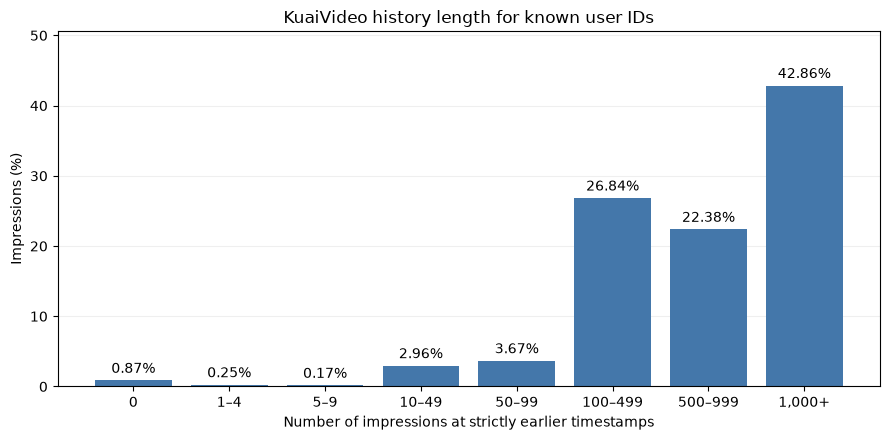

In [11]:
import matplotlib.pyplot as plt

bins = [-1, 0, 4, 9, 49, 99, 499, 999, float('inf')]
labels = ['0', '1–4', '5–9', '10–49', '50–99', '100–499', '500–999', '1,000+']
distribution = pd.cut(history_length, bins=bins, labels=labels).value_counts(sort=False)
percent = 100 * distribution / len(history_length)

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(labels, percent, color='#4477AA')
ax.bar_label(bars, labels=[f'{value:.2f}%' for value in percent], padding=3, fontsize=10)
ax.set(title='KuaiVideo history length for known user IDs',
       xlabel='Number of impressions at strictly earlier timestamps',
       ylabel='Impressions (%)', ylim=(0, percent.max() * 1.18))
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

Timestamp units are undocumented, so history duration in days or hours cannot be established.

In [12]:
missing = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_%': 100 * df.isna().mean(),
})
missing.sort_values('missing_count', ascending=False).round(2)

,missing_count,missing_%
timestamp,0,0.0
user_id,0,0.0
item_id,0,0.0
is_click,0,0.0
is_like,0,0.0
is_follow,0,0.0
pos_items,0,0.0
neg_items,0,0.0
history_length,0,0.0
stored_positive_length,0,0.0


In [13]:
outlier_features = []
# Anomaly flags retain the source values.
rows = []
for column in tqdm(outlier_features, desc='Numerical anomalies', leave=False):
    values = df[column].dropna()
    if values.empty:
        continue
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    if iqr <= 0:
        continue
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    anomalies = int(((values < lower) | (values > upper)).sum())
    rows.append({
        'feature': column, 'min': values.min(), 'max': values.max(),
        'lower bound': lower, 'upper bound': upper,
        'anomalies': anomalies, 'percent of anomalies': 100 * anomalies / len(values),
    })
if rows:
    print('Rule: 1.5 × IQR; percentages use non-missing values.')
    outliers = pd.DataFrame(rows).set_index('feature')
    display(outliers.style.format({
        'min': '{:,.2f}', 'max': '{:,.2f}', 'lower bound': '{:,.2f}',
        'upper bound': '{:,.2f}', 'anomalies': '{:,.0f}',
        'percent of anomalies': '{:.2f}',
    }))
elif outlier_features:
    print('No numerical features with a nonzero IQR.')
else:
    print('No raw numerical features to check.')

No raw numerical features to check.


In [14]:
import numpy as np
from itertools import combinations

matrix_features = ['is_click', 'is_like', 'is_follow', 'item_id']

matrix_sample = df[matrix_features].sample(n=min(1_000_000, len(df)), random_state=42)
codes, margins = {}, {}
# Missing values form a category in this matrix.
for column in matrix_features:
    code, levels = pd.factorize(matrix_sample[column], sort=False, use_na_sentinel=False)
    assert (code >= 0).all()
    codes[column] = code.astype('int64')
    margins[column] = np.bincount(code)

# Bias correction: https://stats.lse.ac.uk/bergsma/pdf/cramerV3.pdf
def corrected_cramers_v(x, y, row_counts, column_counts):
    n, r, k = len(x), len(row_counts), len(column_counts)
    if min(r, k) <= 1:
        return 0.0
    pairs, observed = np.unique(x * k + y, return_counts=True)
    expected = row_counts[pairs // k] * column_counts[pairs % k] / n
    phi_squared = max(0.0, (np.sum(observed.astype(float) ** 2 / expected) - n) / n)
    corrected_phi = max(0.0, phi_squared - (r - 1) * (k - 1) / (n - 1))
    corrected_r = r - (r - 1) ** 2 / (n - 1)
    corrected_k = k - (k - 1) ** 2 / (n - 1)
    denominator = min(corrected_r - 1, corrected_k - 1)
    return float(np.clip(np.sqrt(corrected_phi / denominator), 0, 1)) if denominator > 0 else 0.0

association_matrix = pd.DataFrame(np.eye(len(matrix_features)), index=matrix_features, columns=matrix_features)
for x, y in tqdm(list(combinations(matrix_features, 2)), desc="Cramer's V", unit='pair', leave=False):
    value = corrected_cramers_v(codes[x], codes[y], margins[x], margins[y])
    association_matrix.loc[x, y] = association_matrix.loc[y, x] = value

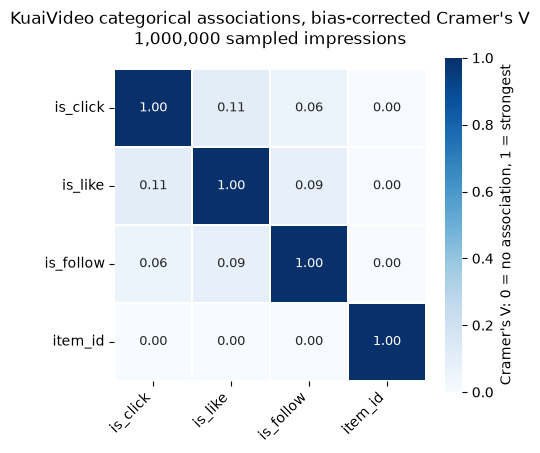

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(5.0, 4.5))
sns.heatmap(association_matrix, vmin=0, vmax=1, cmap='Blues', square=True,
            annot=True, fmt='.2f', annot_kws={'fontsize': 9}, linewidths=.25,
            cbar_kws={'label': "Cramer's V: 0 = no association, 1 = strongest"}, ax=ax)
ax.set_title(f"KuaiVideo categorical associations, bias-corrected Cramer's V\n{len(matrix_sample):,} sampled impressions", pad=18)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_xlabel('')
ax.set_ylabel('')
fig.tight_layout()
plt.show()